# Stacking Regressor – Gross Emissions Alih Fungsi Lahan Sawit

## 1. Import Library

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from itertools import combinations
from matplotlib.ticker import FuncFormatter
from scipy.stats import skew

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit, cross_val_predict
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)


seed_everything(42)


def show(title, d, n=5):
    print(f'\n{title}')
    display(d.head(n).round(4))

## 2. Load File

In [2]:
df = pd.read_csv('Gross_emissions.csv')
print(f"Dimensi data: {df.shape}")
df.head()

Dimensi data: (5140, 11)


,year,country,country_iso2,region,region_trase_id,parent_region,parent_region_trase_id,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,gross_emissions_from_land-use_change_tonnes_co₂-equivalent
0,2015,INDONESIA,ID,ACEH BARAT,ID-1105,ACEH,ID-11,14.708201,1557.828843,17364.223327,24963.918394
1,2015,INDONESIA,ID,ACEH BARAT DAYA,ID-1112,ACEH,ID-11,115.961861,92.723915,6330.203873,74820.238382
2,2015,INDONESIA,ID,ACEH BESAR,ID-1106,ACEH,ID-11,0.000000,0.000000,0.000000,0.000000
3,2015,INDONESIA,ID,ACEH JAYA,ID-1114,ACEH,ID-11,190.813083,0.000000,3640.236017,141059.342325
4,2015,INDONESIA,ID,ACEH SELATAN,ID-1101,ACEH,ID-11,0.000000,0.000000,2917.933327,0.000000


## 3. EDA Data Awal

### 3.1 Statistik Deskriptif

In [3]:
num_cols = ['annual_palm_deforestation_(industrial)_hectares',
            'oil_palm_planted_on_peat_hectares',
            'oil_palm_planted_area_hectares',
            'gross_emissions_from_land-use_change_tonnes_co₂-equivalent']
cat_cols = ['year', 'region', 'parent_region']
target = 'gross_emissions_from_land-use_change_tonnes_co₂-equivalent'
features = [c for c in num_cols if c != target]
short = lambda s: s[:30]


def describe_num(d):
    out = d[num_cols].describe().T
    out['skewness'] = d[num_cols].apply(lambda x: skew(x))
    out['zero_count'] = d[num_cols].apply(lambda x: (x == 0).sum())
    out['zero_percentage (%)'] = out['zero_count'] / len(d) * 100
    out['missing_count'] = d[num_cols].isna().sum()
    return out.round(2)


def describe_cat(d, cols):
    for col in cols:
        print(f"\nVariabel '{col}': {d[col].nunique()} nilai unik")
        print(d[col].value_counts().head(5))


print("A) Statistik Deskriptif Variabel Numerik")
display(describe_num(df))
print("\nB) Analisis Variabel Kategorikal")
describe_cat(df, cat_cols)
print("\nMissing value per kolom:")
print(df.isnull().sum())

A) Statistik Deskriptif Variabel Numerik


,count,mean,std,min,25%,50%,75%,max,skewness,zero_count,zero_percentage (%),missing_count
annual_palm_deforestation_(industrial)_hectares,5140.0,94.46,609.93,0.0,0.0,0.0,0.00,19897.10,15.80,4251,82.70,0
oil_palm_planted_on_peat_hectares,5140.0,2956.08,11609.32,0.0,0.0,0.0,0.00,122848.33,5.75,4278,83.23,0
oil_palm_planted_area_hectares,5140.0,19431.20,54130.16,0.0,0.0,0.0,7148.42,507422.20,4.81,3244,63.11,0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent,5140.0,113964.78,561589.87,0.0,0.0,0.0,0.00,13224015.90,11.10,3940,76.65,0



B) Analisis Variabel Kategorikal

Variabel 'year': 10 nilai unik
year
2015    514
2016    514
2017    514
2018    514
2019    514
Name: count, dtype: int64

Variabel 'region': 514 nilai unik
region
ACEH BARAT         10
ACEH BARAT DAYA    10
ACEH BESAR         10
ACEH JAYA          10
ACEH SELATAN       10
Name: count, dtype: int64

Variabel 'parent_region': 38 nilai unik
parent_region
JAWA TIMUR          380
JAWA TENGAH         350
SUMATERA UTARA      330
JAWA BARAT          270
SULAWESI SELATAN    240
Name: count, dtype: int64

Missing value per kolom:
year                                                          0
country                                                       0
country_iso2                                                  0
region                                                        0
region_trase_id                                               0
parent_region                                                 0
parent_region_trase_id                                

### 3.2 Distribusi Variabel

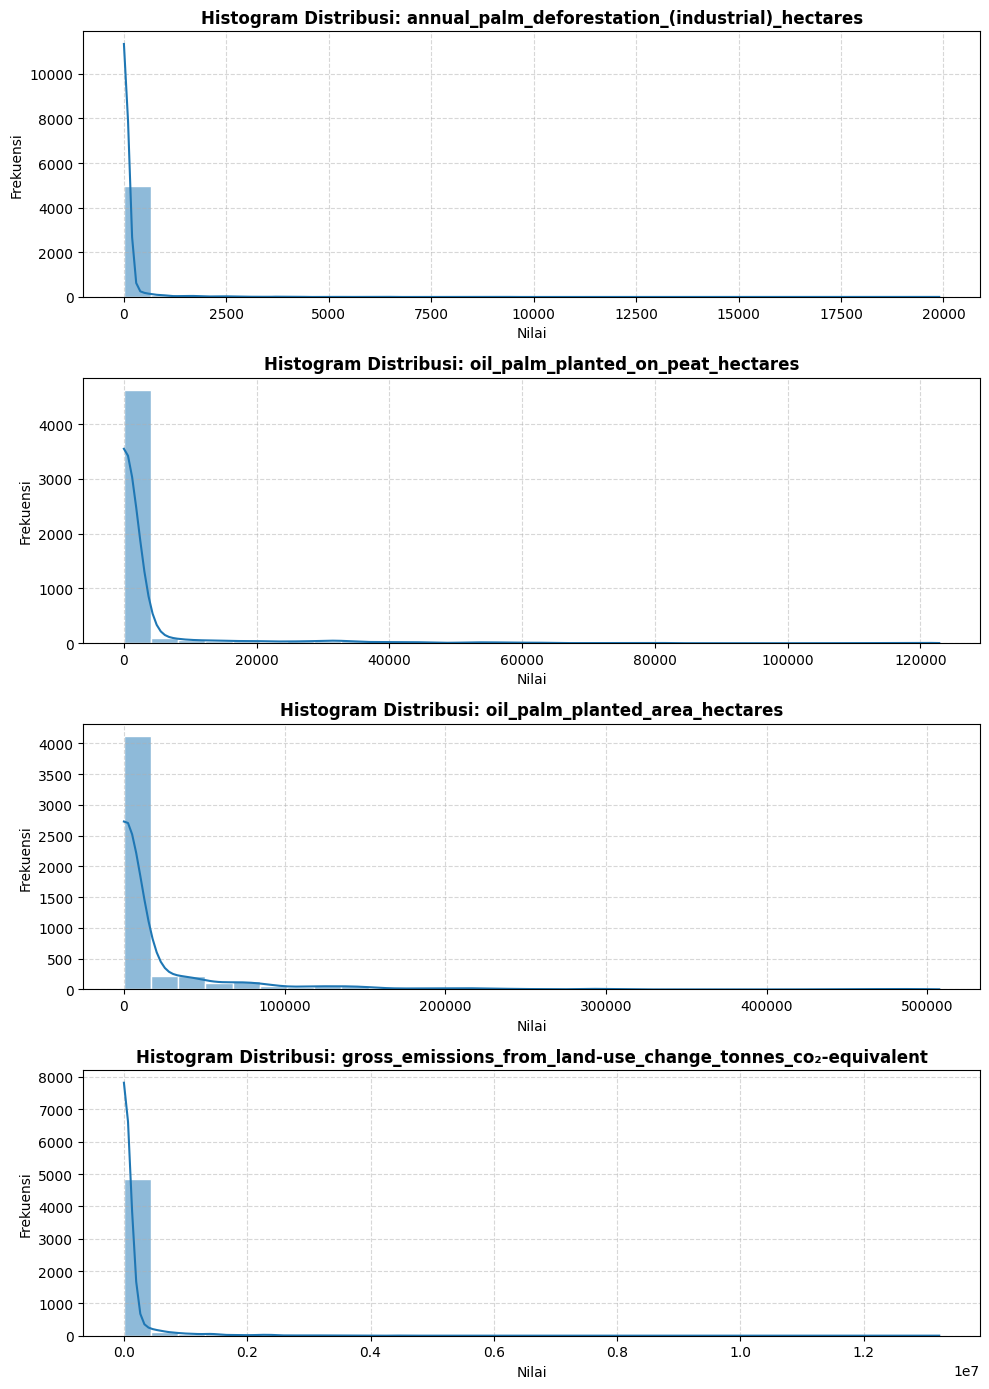

In [4]:
n_cols = len(num_cols)
fig, axes = plt.subplots(nrows=n_cols, ncols=1, figsize=(10, 3.5 * n_cols))

for i, col in enumerate(num_cols):
  sns.histplot(
      data=df,
      x=col,
      kde=True,
      ax=axes[i],
      color='#1f77b4',
      bins=30,
      edgecolor='white',
  )
  axes[i].set_title(
      f'Histogram Distribusi: {col}',
      fontweight='bold',
  )
  axes[i].set_xlabel('Nilai')
  axes[i].set_ylabel('Frekuensi')
  axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Split Data & Cleaning
Split dilakukan lebih dulu. Wilayah aktif ditentukan hanya dari data latih (2015–2022), lalu diterapkan ke data latih dan uji.

In [5]:
cols_to_drop = ['country', 'country_iso2', 'region_trase_id', 'parent_region', 'parent_region_trase_id']
df_clean = df.drop(columns=cols_to_drop, errors='ignore')
assert df_clean['year'].is_monotonic_increasing, "Data belum urut tahun"
assert (df_clean[num_cols] >= 0).all().all(), "Ada nilai negatif"

train_raw = df_clean[df_clean['year'] <= 2022]
test_raw = df_clean[df_clean['year'] >= 2023]

region_activity = train_raw.groupby('region')[num_cols].apply(lambda x: x.abs().sum().sum())
active_regions = region_activity[region_activity > 0].index
inactive_regions = region_activity[region_activity == 0].index

train_df = train_raw[train_raw['region'].isin(active_regions)].reset_index(drop=True)
test_df = test_raw[test_raw['region'].isin(active_regions)].reset_index(drop=True)

ids_train, ids_test = train_df[['year', 'region']], test_df[['year', 'region']]
X_train, y_train = train_df[features].copy(), train_df[target].copy()
X_test, y_test = test_df[features].copy(), test_df[target].copy()

print(f"Total kabupaten awal            : {df['region'].nunique()}")
print(f"Kabupaten aktif (data latih)    : {len(active_regions)}")
print(f"Kabupaten tidak aktif (dihapus) : {len(inactive_regions)}")
print(f"Baris latih: {len(train_raw)} -> {len(train_df)}")
print(f"Baris uji  : {len(test_raw)} -> {len(test_df)}")
print(f"\nDimensi X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Dimensi X_test : {X_test.shape}, y_test: {y_test.shape}")

Total kabupaten awal            : 514
Kabupaten aktif (data latih)    : 195
Kabupaten tidak aktif (dihapus) : 319
Baris latih: 4112 -> 1560
Baris uji  : 1028 -> 390

Dimensi X_train: (1560, 3), y_train: (1560,)
Dimensi X_test : (390, 3), y_test: (390,)


## 5. EDA Setelah Cleaning (Data Latih)

### 5.1 Statistik Deskriptif

In [6]:
all_df = pd.concat([train_df, test_df], ignore_index=True)

print(f"Data gabungan: {all_df.shape[0]} baris, {all_df['region'].nunique()} kabupaten, "
      f"tahun {all_df['year'].min()}-{all_df['year'].max()}\n")
print("A) Statistik Deskriptif Variabel Numerik")
display(describe_num(all_df))
print("\nB) Analisis Variabel Kategorikal")
describe_cat(all_df, ['year', 'region'])
print("\nMissing value:")
print(all_df[num_cols].isnull().sum())

Data gabungan: 1950 baris, 195 kabupaten, tahun 2015-2024

A) Statistik Deskriptif Variabel Numerik


,count,mean,std,min,25%,50%,75%,max,skewness,zero_count,zero_percentage (%),missing_count
annual_palm_deforestation_(industrial)_hectares,1950.0,248.98,970.78,0.0,0.0,0.00,65.66,19897.10,9.85,1063,54.51,0
oil_palm_planted_on_peat_hectares,1950.0,7791.93,17823.29,0.0,0.0,0.00,5513.85,122848.33,3.36,1088,55.79,0
oil_palm_planted_area_hectares,1950.0,51218.66,78082.58,0.0,4995.6,19769.02,68631.14,507422.20,2.96,54,2.77,0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent,1950.0,300369.77,880661.65,0.0,0.0,12745.78,194112.33,13224015.90,6.95,752,38.56,0



B) Analisis Variabel Kategorikal

Variabel 'year': 10 nilai unik
year
2015    195
2016    195
2017    195
2018    195
2019    195
Name: count, dtype: int64

Variabel 'region': 195 nilai unik
region
ACEH BARAT         10
ACEH BARAT DAYA    10
ACEH JAYA          10
ACEH SELATAN       10
ACEH SINGKIL       10
Name: count, dtype: int64

Missing value:
annual_palm_deforestation_(industrial)_hectares               0
oil_palm_planted_on_peat_hectares                             0
oil_palm_planted_area_hectares                                0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent    0
dtype: int64


In [7]:
print("A) Statistik Deskriptif Variabel Numerik")
display(describe_num(train_df))
print("\nB) Analisis Variabel Kategorikal")
describe_cat(train_df, ['year', 'region'])
print("\nMissing value:")
print(train_df[num_cols].isnull().sum())

A) Statistik Deskriptif Variabel Numerik


,count,mean,std,min,25%,50%,75%,max,skewness,zero_count,zero_percentage (%),missing_count
annual_palm_deforestation_(industrial)_hectares,1560.0,268.96,1037.15,0.0,0.00,0.00,67.18,19897.10,9.54,831,53.27,0
oil_palm_planted_on_peat_hectares,1560.0,7648.86,17521.00,0.0,0.00,0.00,5370.37,120295.04,3.36,874,56.03,0
oil_palm_planted_area_hectares,1560.0,50307.02,76865.81,0.0,4702.75,19626.52,66649.87,495798.77,2.96,51,3.27,0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent,1560.0,313174.30,933112.93,0.0,0.00,14091.56,197947.51,13224015.90,6.91,582,37.31,0



B) Analisis Variabel Kategorikal

Variabel 'year': 8 nilai unik
year
2015    195
2016    195
2017    195
2018    195
2019    195
Name: count, dtype: int64

Variabel 'region': 195 nilai unik
region
ACEH BARAT         8
ACEH BARAT DAYA    8
ACEH JAYA          8
ACEH SELATAN       8
ACEH SINGKIL       8
Name: count, dtype: int64

Missing value:
annual_palm_deforestation_(industrial)_hectares               0
oil_palm_planted_on_peat_hectares                             0
oil_palm_planted_area_hectares                                0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent    0
dtype: int64


In [8]:
print("A) Statistik Deskriptif Variabel Numerik")
display(describe_num(test_df))
print("\nB) Analisis Variabel Kategorikal")
describe_cat(test_df, ['year', 'region'])
print("\nMissing value:")
print(test_df[num_cols].isnull().sum())

A) Statistik Deskriptif Variabel Numerik


,count,mean,std,min,25%,50%,75%,max,skewness,zero_count,zero_percentage (%),missing_count
annual_palm_deforestation_(industrial)_hectares,390.0,169.02,634.59,0.0,0.00,0.00,56.81,9317.20,9.25,232,59.49,0
oil_palm_planted_on_peat_hectares,390.0,8364.21,18997.24,0.0,0.00,0.00,5890.40,122848.33,3.34,214,54.87,0
oil_palm_planted_area_hectares,390.0,54865.19,82773.78,0.0,5317.92,21172.50,73137.75,507422.20,2.93,3,0.77,0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent,390.0,249151.66,626895.71,0.0,0.00,8865.02,162666.84,6202993.41,4.98,170,43.59,0



B) Analisis Variabel Kategorikal

Variabel 'year': 2 nilai unik
year
2023    195
2024    195
Name: count, dtype: int64

Variabel 'region': 195 nilai unik
region
ACEH BARAT         2
ACEH BARAT DAYA    2
ACEH JAYA          2
ACEH SELATAN       2
ACEH SINGKIL       2
Name: count, dtype: int64

Missing value:
annual_palm_deforestation_(industrial)_hectares               0
oil_palm_planted_on_peat_hectares                             0
oil_palm_planted_area_hectares                                0
gross_emissions_from_land-use_change_tonnes_co₂-equivalent    0
dtype: int64


### 5.2 Distribusi, Mean & Median

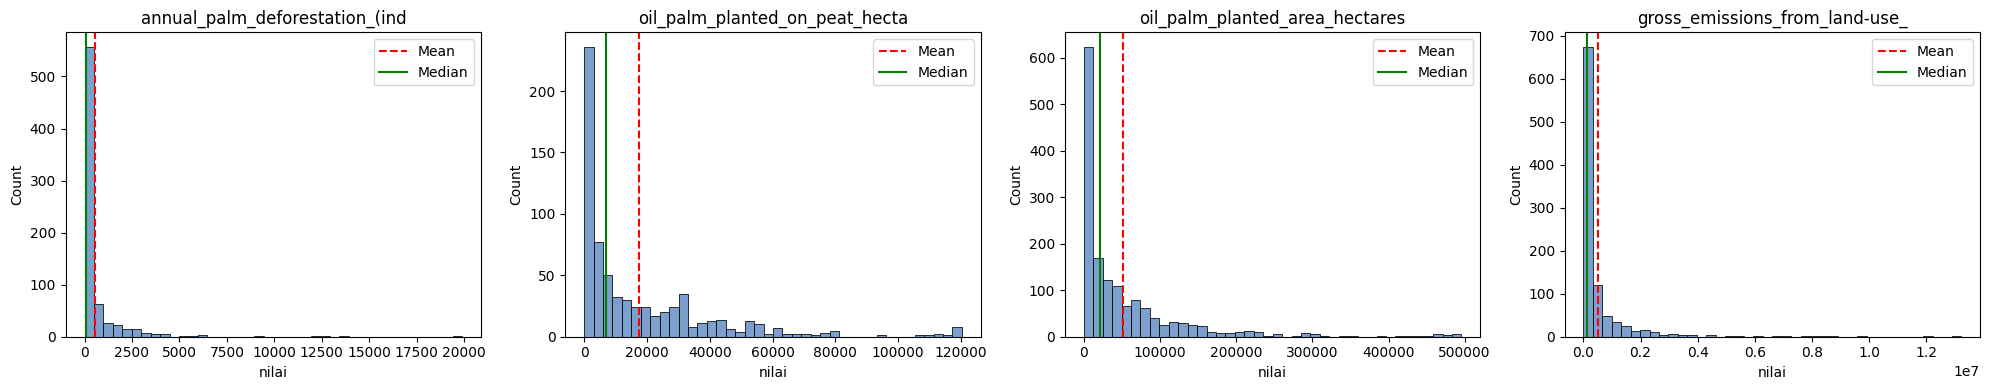

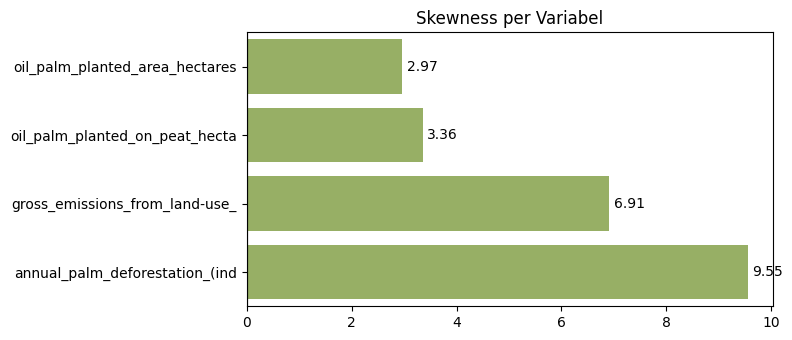

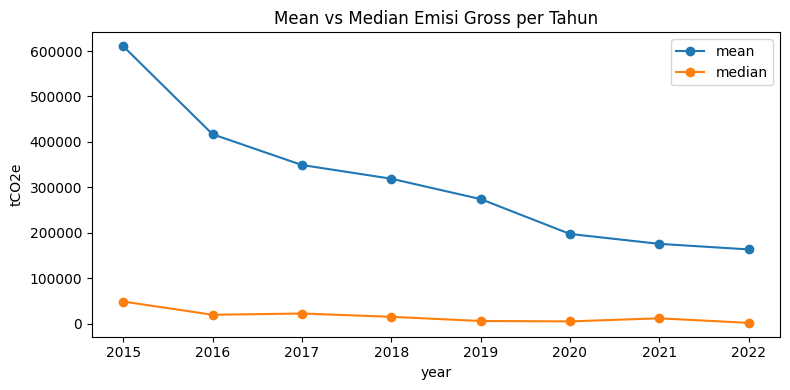

In [9]:
# histogram + garis mean & median (hanya nilai > 0)
fig, axes = plt.subplots(1, len(num_cols), figsize=(5 * len(num_cols), 4))
for ax, c in zip(axes, num_cols):
    x = train_df.loc[train_df[c] > 0, c]
    sns.histplot(x, bins=40, ax=ax, color="#4f81bd")
    ax.axvline(x.mean(), color="red", ls="--", label="Mean")
    ax.axvline(x.median(), color="green", ls="-", label="Median")
    ax.set_title(c[:30])
    ax.set_xlabel("nilai")
    ax.legend()
plt.tight_layout()
plt.savefig("desk_hist_mean_median.png", dpi=150)

# bar chart skewness per variabel
skew_series = train_df[num_cols].skew().sort_values()
plt.figure(figsize=(8, 3.5))
ax = sns.barplot(x=skew_series.values, y=[s[:30] for s in skew_series.index], color="#9bbb59")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.axvline(0, color="black", lw=0.8)
plt.title("Skewness per Variabel")
plt.tight_layout()
plt.savefig("desk_skewness.png", dpi=150)

# mean vs median per tahun (target)
target = [c for c in num_cols if "gross_emissions" in c][0]
per_tahun = train_df.groupby("year")[target].agg(["mean", "median"])
per_tahun.plot(marker="o", figsize=(8, 4))
plt.ylabel("tCO2e")
plt.title("Mean vs Median Emisi Gross per Tahun")
plt.tight_layout()
plt.savefig("desk_mean_median_tahun.png", dpi=150)
plt.show()

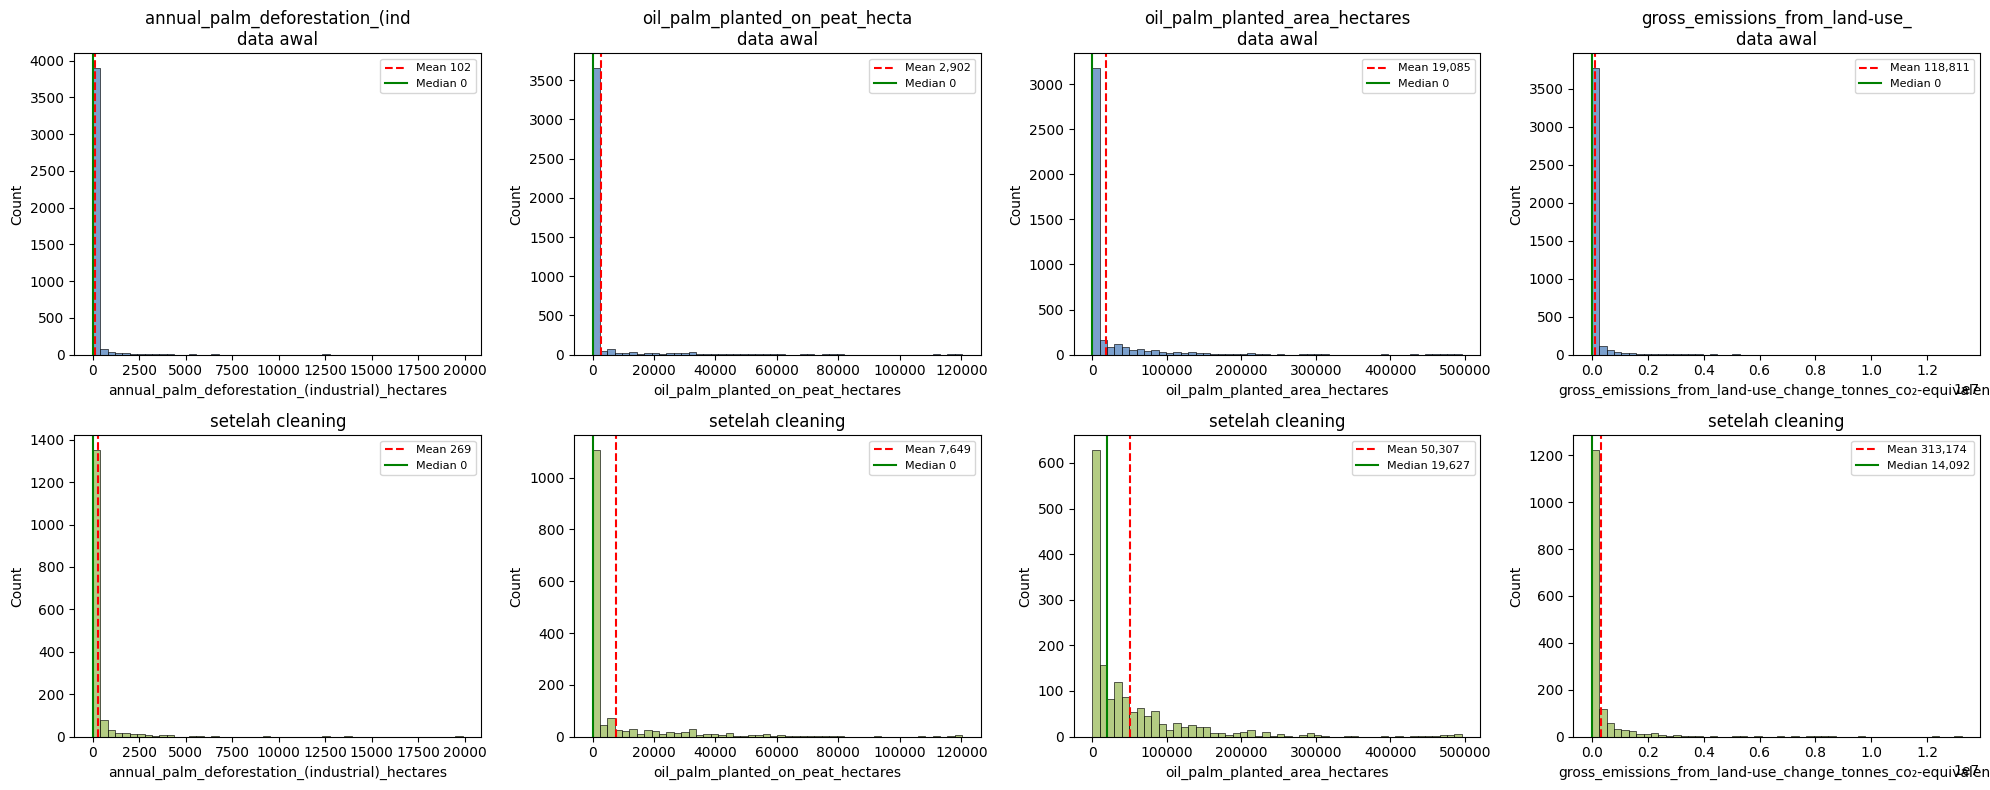

In [10]:
fig, axes = plt.subplots(2, len(num_cols), figsize=(5 * len(num_cols), 8))

for j, c in enumerate(num_cols):
    x = train_raw[c]

    # baris 1: data awal
    sns.histplot(x, bins=50, ax=axes[0, j], color="#4f81bd")
    axes[0, j].axvline(x.mean(), color="red", ls="--", label=f"Mean {x.mean():,.0f}")
    axes[0, j].axvline(x.median(), color="green", ls="-", label=f"Median {x.median():,.0f}")
    axes[0, j].set_title(f"{c[:30]}\ndata awal")
    axes[0, j].legend(fontsize=8)

    # baris 2: setelah cleaning
    xp = train_df[c]
    sns.histplot(xp, bins=50, ax=axes[1, j], color="#9bbb59")
    axes[1, j].axvline(xp.mean(), color="red", ls="--", label=f"Mean {xp.mean():,.0f}")
    axes[1, j].axvline(xp.median(), color="green", ls="-", label=f"Median {xp.median():,.0f}")
    axes[1, j].set_title("setelah cleaning")
    axes[1, j].legend(fontsize=8)

plt.tight_layout()
plt.savefig("desk_hist_clean.png", dpi=150)
plt.show()

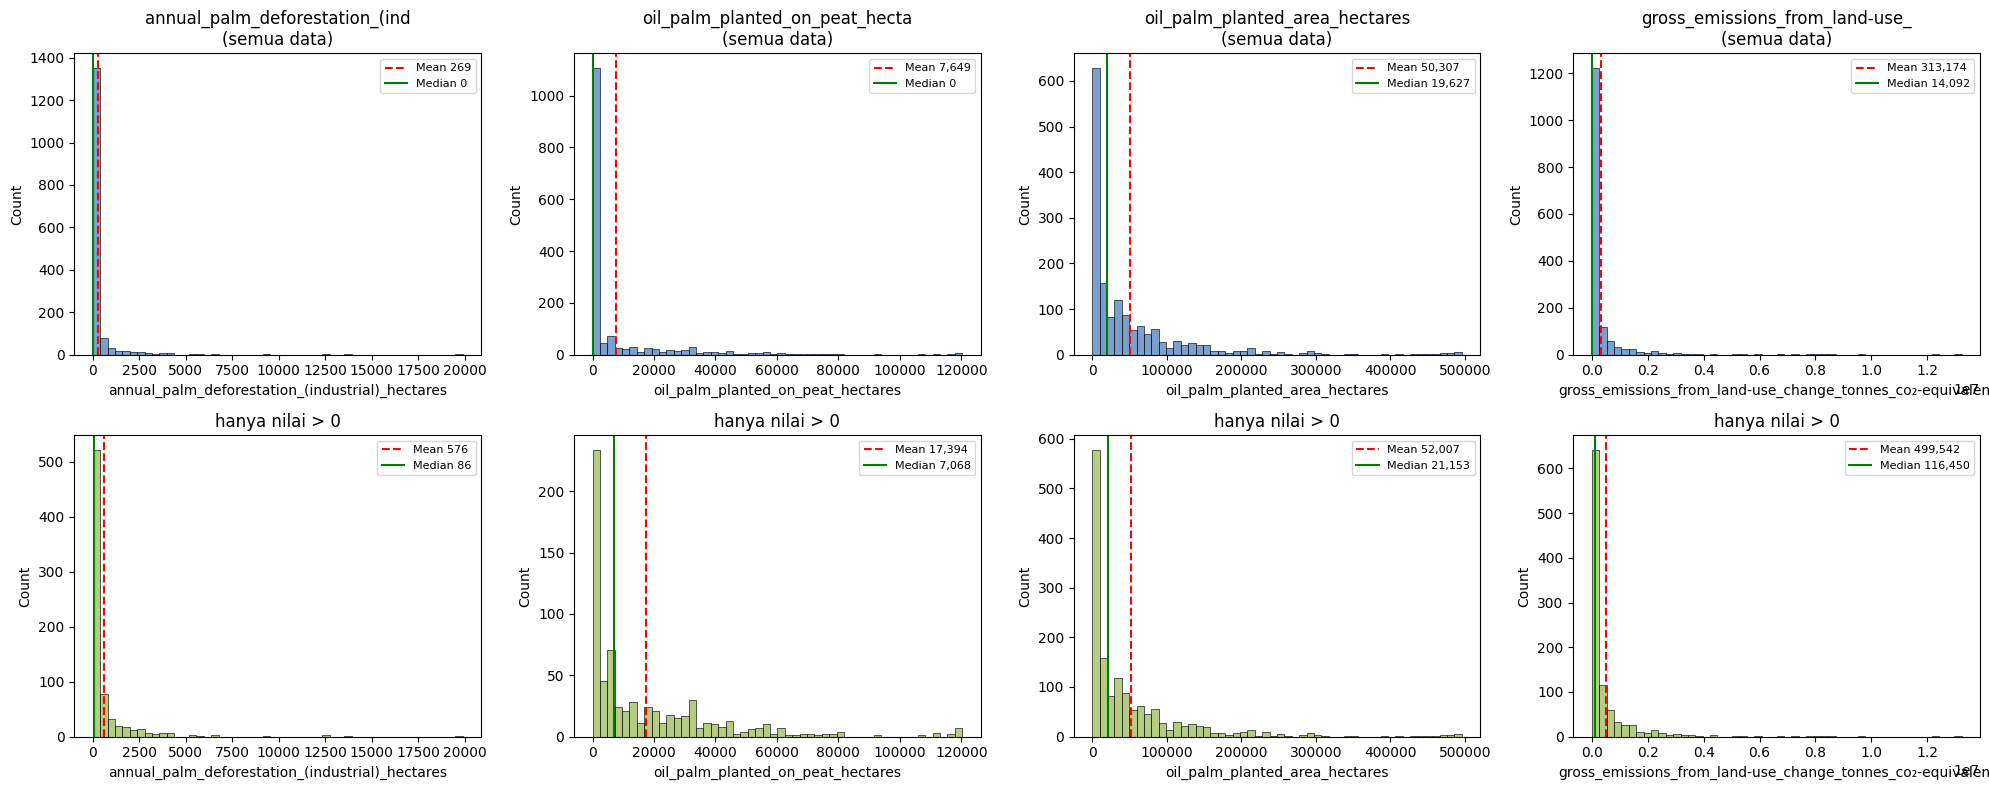

In [11]:
fig, axes = plt.subplots(2, len(num_cols), figsize=(5 * len(num_cols), 8))

for j, c in enumerate(num_cols):
    x = train_df[c]

    # baris 1: semua data (termasuk nol)
    sns.histplot(x, bins=50, ax=axes[0, j], color="#4f81bd")
    axes[0, j].axvline(x.mean(), color="red", ls="--", label=f"Mean {x.mean():,.0f}")
    axes[0, j].axvline(x.median(), color="green", ls="-", label=f"Median {x.median():,.0f}")
    axes[0, j].set_title(f"{c[:30]}\n(semua data)")
    axes[0, j].legend(fontsize=8)

    # baris 2: hanya nilai > 0
    xp = x[x > 0]
    sns.histplot(xp, bins=50, ax=axes[1, j], color="#9bbb59")
    axes[1, j].axvline(xp.mean(), color="red", ls="--", label=f"Mean {xp.mean():,.0f}")
    axes[1, j].axvline(xp.median(), color="green", ls="-", label=f"Median {xp.median():,.0f}")
    axes[1, j].set_title("hanya nilai > 0")
    axes[1, j].legend(fontsize=8)

plt.tight_layout()
plt.savefig("desk_hist_skala_asli.png", dpi=150)
plt.show()

### 5.3 Proporsi Nilai Nol

                                                            nol_mutlak  bukan_nol  antara_0_dan_1  total  nol_%  bukan_nol_%
annual_palm_deforestation_(industrial)_hectares                    831        729              42   1560  53.27        46.73
oil_palm_planted_on_peat_hectares                                  874        686              22   1560  56.03        43.97
oil_palm_planted_area_hectares                                      51       1509              44   1560   3.27        96.73
gross_emissions_from_land-use_change_tonnes_co₂-equivalent         582        978               1   1560  37.31        62.69


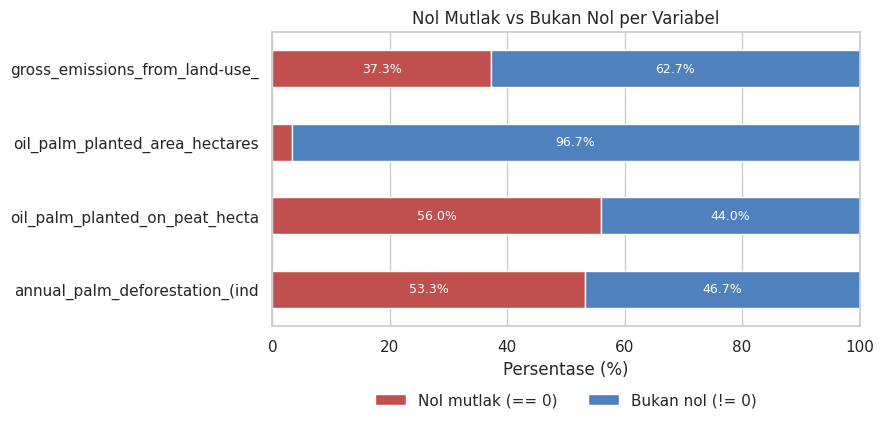

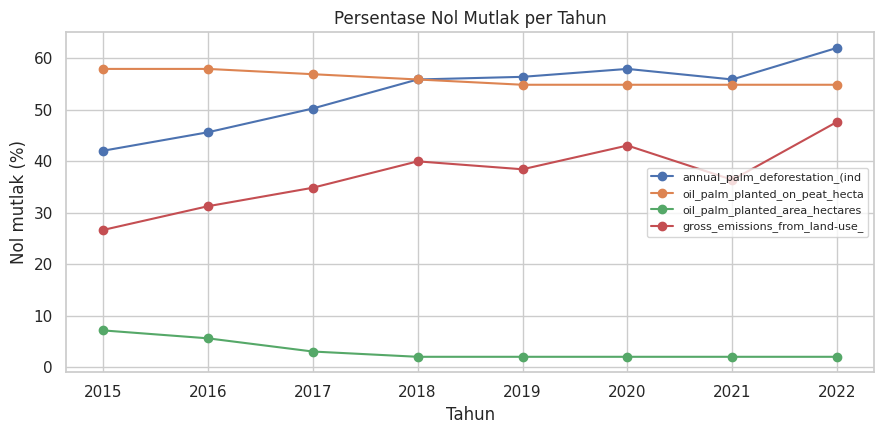

In [12]:
sns.set_theme(style="whitegrid")


# tabel ringkasan nol dan bukan nol
ringkas = pd.DataFrame({
    "nol_mutlak": (train_df[num_cols] == 0).sum(),
    "bukan_nol": (train_df[num_cols] != 0).sum(),
    "antara_0_dan_1": ((train_df[num_cols] > 0) & (train_df[num_cols] < 1)).sum(),
})
ringkas["total"] = ringkas["nol_mutlak"] + ringkas["bukan_nol"]
ringkas["nol_%"] = (ringkas["nol_mutlak"] / ringkas["total"] * 100).round(2)
ringkas["bukan_nol_%"] = (100 - ringkas["nol_%"]).round(2)
print(ringkas.to_string())

# stacked bar proporsi nol dan bukan nol per variabel
plot_df = ringkas[["nol_%", "bukan_nol_%"]].copy()
plot_df.index = [short(c) for c in plot_df.index]

ax = plot_df.plot(kind="barh", stacked=True, figsize=(9, 4.5),
                  color=["#c0504d", "#4f81bd"], legend=False)

# label persen
for cont in ax.containers:
    labels = [f"{v:.1f}%" if v >= 5 else "" for v in cont.datavalues]
    ax.bar_label(cont, labels=labels, label_type="center", color="white", fontsize=9)

ax.set_xlim(0, 100)
ax.set_xlabel("Persentase (%)")
ax.set_title("Nol Mutlak vs Bukan Nol per Variabel")

# legenda
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Nol mutlak (== 0)", "Bukan nol (!= 0)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, frameon=False)

plt.tight_layout()
plt.savefig("nol_vs_bukan_nol.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------
# 3. TREN PERSENTASE NOL MUTLAK PER TAHUN
# ---------------------------------------------------------------
nol_tahun = train_df.groupby("year")[list(num_cols)].agg(lambda s: (s == 0).mean() * 100)

plt.figure(figsize=(9, 4.5))
for c in num_cols:
    plt.plot(nol_tahun.index, nol_tahun[c], marker="o", label=short(c))
plt.xticks(nol_tahun.index)
plt.ylabel("Nol mutlak (%)")
plt.xlabel("Tahun")
plt.title("Persentase Nol Mutlak per Tahun")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("nol_per_tahun.png", dpi=150)
plt.show()

### 5.4 Korelasi

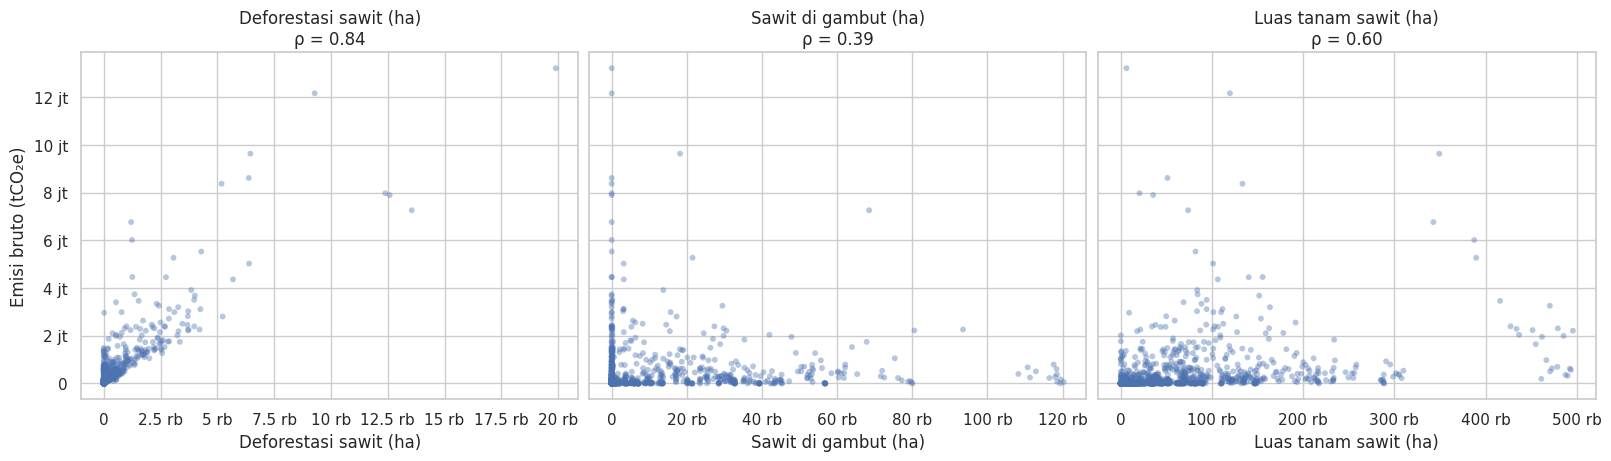

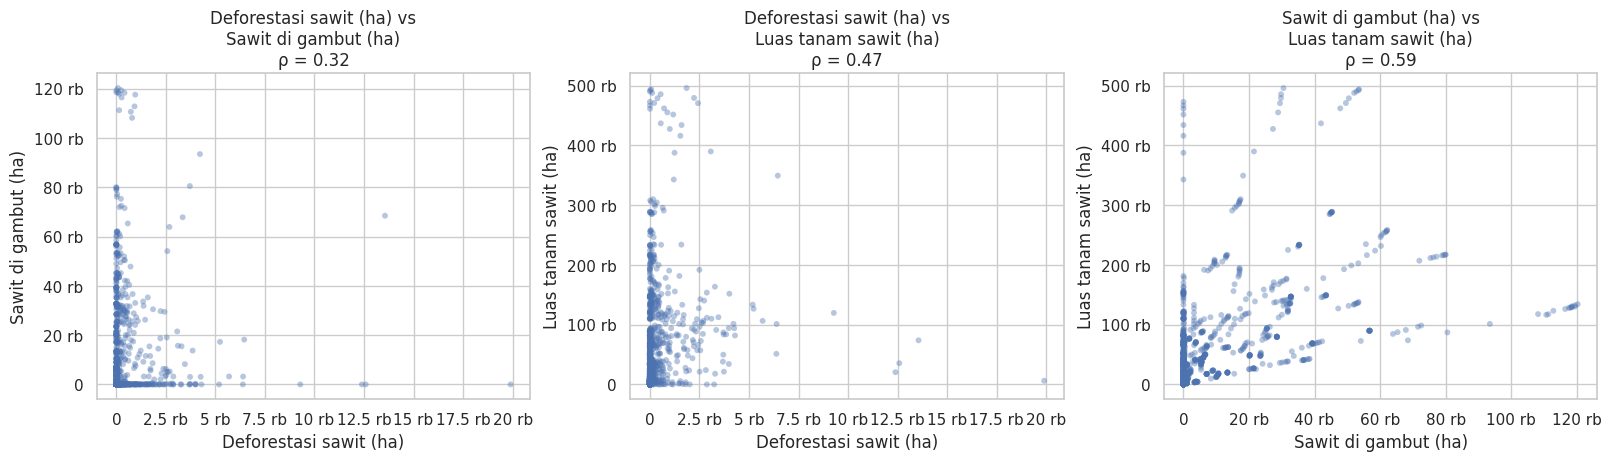

In [13]:
from itertools import combinations
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")

LABEL = {
    "deforestation": "Deforestasi sawit (ha)",
    "peat": "Sawit di gambut (ha)",
    "planted_area": "Luas tanam sawit (ha)",
    "gross_emissions": "Emisi bruto (tCO₂e)",
}
pretty = lambda c: next(v for k, v in LABEL.items() if k in c)
fmt = FuncFormatter(lambda x, _: f"{x/1e6:g} jt" if x >= 1e6 else f"{x/1e3:g} rb" if x >= 1e3 else f"{x:g}")

fitur = features

# 1. Fitur vs target
fig, axes = plt.subplots(1, len(fitur), figsize=(16, 4.5), sharey=True, constrained_layout=True)
for ax, c in zip(axes, fitur):
    sns.scatterplot(data=train_df, x=c, y=target, alpha=0.4, s=18, edgecolor="none", ax=ax)
    rho = train_df[c].corr(train_df[target], method="spearman")
    ax.set(title=f"{pretty(c)}\nρ = {rho:.2f}", xlabel=pretty(c), ylabel=pretty(target))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)
    ax.label_outer()
fig.savefig("scatter_skala_asli.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Antar prediktor (berjejer ke samping, tanpa diagonal)
pasangan = list(combinations(fitur, 2))
fig, axes = plt.subplots(1, len(pasangan), figsize=(16, 4.5), constrained_layout=True)
for ax, (x, y) in zip(axes, pasangan):
    sns.scatterplot(data=train_df, x=x, y=y, alpha=0.4, s=18, edgecolor="none", ax=ax)
    rho = train_df[x].corr(train_df[y], method="spearman")
    ax.set(title=f"{pretty(x)} vs\n{pretty(y)}\nρ = {rho:.2f}", xlabel=pretty(x), ylabel=pretty(y))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)
fig.savefig("scatter_antar_prediktor.png", dpi=150, bbox_inches="tight")
plt.show()

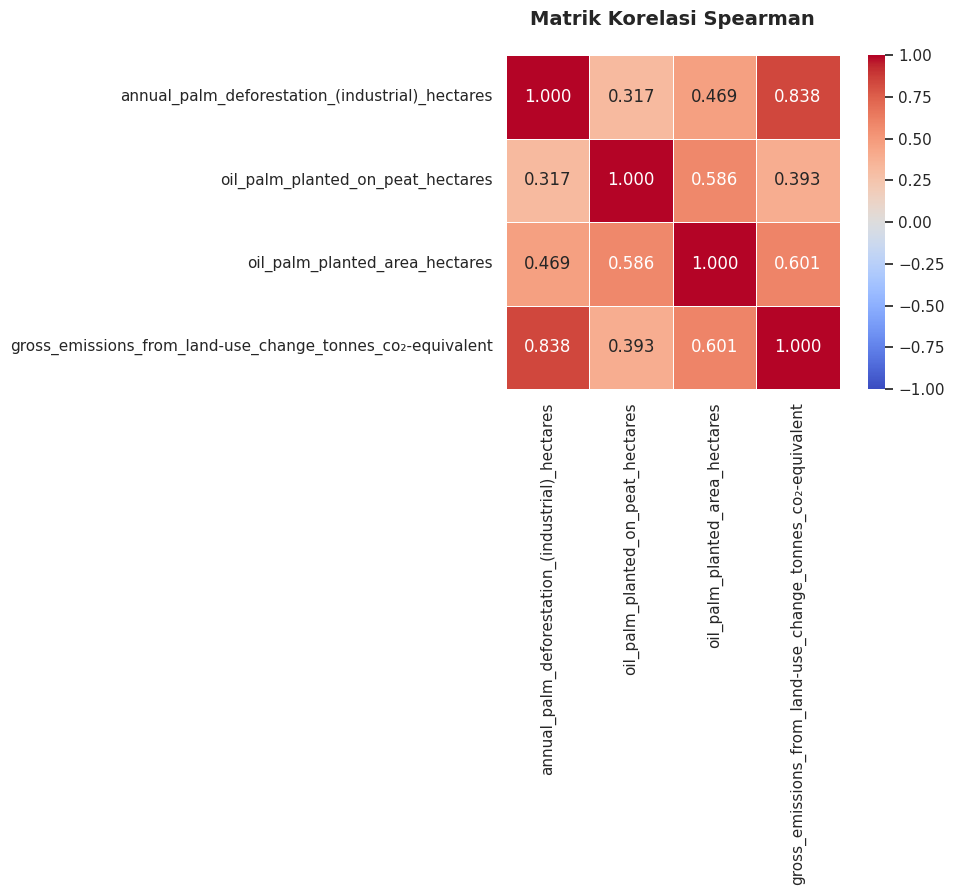

In [14]:
spearman_cor = train_df[num_cols].corr(method='spearman')
plt.figure(figsize=(11, 9))
sns.heatmap(
    spearman_cor,
    annot=True,
    cmap='coolwarm',
    fmt=".3f",
    linewidths=0.5,
    square=True,
    vmin=-1,
    vmax=1)
plt.title('Matrik Korelasi Spearman\n',fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Pipeline Preprocessing
Preprocessing menjadi bagian dari model, sehingga di-fit hanya pada data latih (atau fold latih saat cross-validation).

In [15]:
x_pipe = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', RobustScaler())
])

preprocessor = ColumnTransformer(
    transformers=[('num', x_pipe, features)],
    remainder='drop'
)

y_pipe = Pipeline([
    ('log', FunctionTransformer(np.log1p, inverse_func=np.expm1)),
    ('scaler', RobustScaler())
])

## 7. Pemodelan

### 7.1 Hyperparameter Tuning

In [16]:
model_grids = {
    'Gradient Boosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'params': {
            'regressor__model__n_estimators': [50, 100, 150],
            'regressor__model__learning_rate': [0.01, 0.03, 0.05],
            'regressor__model__max_depth': [2, 3, 4],
            'regressor__model__min_samples_leaf': [10, 15, 20]
        }
    },
    'SVR': {
        'model': SVR(),
        'params': {
            'regressor__model__C': [0.1, 1, 10],
            'regressor__model__epsilon': [0.05, 0.01, 0.1, 0.2],
            'regressor__model__kernel': ['rbf', 'linear'],
            'regressor__model__gamma': [0.05, 1.0, 10.0]
        }
    },
    'KNN': {
        'model': KNeighborsRegressor(),
        'params': {
            'regressor__model__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17],
            'regressor__model__weights': ['uniform', 'distance'],
            'regressor__model__metric': ['euclidean', 'manhattan']
        }
    }
}

In [17]:
tscv = TimeSeriesSplit(n_splits=3)

results, best_estimators = [], {}
for name, config in model_grids.items():
    model = TransformedTargetRegressor(
        regressor=Pipeline([('prep', preprocessor), ('model', config['model'])]),
        transformer=y_pipe
    )
    gs = GridSearchCV(
        estimator=model,
        param_grid=config['params'],
        scoring='neg_root_mean_squared_error',
        cv=tscv,
        n_jobs=-1,
    )

    t0 = time.perf_counter()
    gs.fit(X_train, y_train)
    t_tuning = time.perf_counter() - t0
    best_estimators[name] = gs.best_estimator_
    results.append({'Model': name,
                    'CV RMSE': -gs.best_score_,
                    'Best Params': gs.best_params_,
                    'Waktu Tuning (s)': t_tuning,
                    'Waktu Fit Final (s)': gs.refit_time_})

df_tuning = pd.DataFrame(results).sort_values('CV RMSE').reset_index(drop=True)
for _, r in df_tuning.iterrows():
    print(f"\n{r['Model']}\n  CV RMSE     : {r['CV RMSE']:,.2f}\n  Best Params : {r['Best Params']}"
          f"\n  Waktu tuning: {r['Waktu Tuning (s)']:.2f} s | Fit final: {r['Waktu Fit Final (s)']:.4f} s")


SVR
  CV RMSE     : 296,829.43
  Best Params : {'regressor__model__C': 0.1, 'regressor__model__epsilon': 0.01, 'regressor__model__gamma': 0.05, 'regressor__model__kernel': 'rbf'}
  Waktu tuning: 21.30 s | Fit final: 0.1082 s

KNN
  CV RMSE     : 341,504.67
  Best Params : {'regressor__model__metric': 'euclidean', 'regressor__model__n_neighbors': 3, 'regressor__model__weights': 'uniform'}
  Waktu tuning: 1.75 s | Fit final: 0.0106 s

Gradient Boosting
  CV RMSE     : 347,044.47
  Best Params : {'regressor__model__learning_rate': 0.05, 'regressor__model__max_depth': 4, 'regressor__model__min_samples_leaf': 15, 'regressor__model__n_estimators': 150}
  Waktu tuning: 35.20 s | Fit final: 0.4007 s


### 7.2 Stacking
Memakai `StackingRegressor` bawaan sklearn. Setiap base learner berupa `Pipeline` (log1p → RobustScaler → model), dan transformasi target berada di luar stacking lewat `TransformedTargetRegressor`.

In [18]:
def base(name):
    return clone(best_estimators[name].regressor)


stack_configs = {
    'Stacking GB + KNN + SVR': [('gb', 'Gradient Boosting'), ('knn', 'KNN'), ('svr', 'SVR')]
}

stack_models, stack_fit_time = {}, {}
for name, members in stack_configs.items():
    stack = StackingRegressor(
        estimators=[(key, base(model)) for key, model in members],
        final_estimator=Ridge(random_state=42),
        cv=KFold(n_splits=3, shuffle=False),
    )
    t0 = time.perf_counter()
    stack_models[name] = TransformedTargetRegressor(regressor=stack, transformer=y_pipe).fit(X_train, y_train)
    stack_fit_time[name] = time.perf_counter() - t0

all_models = {**best_estimators, **stack_models}

### 7.3 Out-of-Fold Base Learner


In [19]:
LABEL = {'gb': 'GB', 'svr': 'SVR', 'knn': 'KNN'}

oof_tables = {}
for name, model in stack_models.items():
    stack = model.regressor_
    y_scaled = model.transformer_.transform(y_train.to_frame()).ravel()

    oof = np.column_stack([
        cross_val_predict(clone(est), X_train, y_scaled, cv=stack.cv)
        for est in stack.estimators_
    ])

    # pastikan identik dengan data yang dipakai StackingRegressor untuk melatih Ridge
    refit = clone(stack.final_estimator).fit(oof, y_scaled)
    assert np.allclose(refit.coef_, stack.final_estimator_.coef_)

    table = pd.DataFrame(oof, columns=[f'OOF_{LABEL[k]}' for k in stack.named_estimators_])
    table.insert(0, 'target_scaled', y_scaled)
    oof_tables[name] = pd.concat([ids_train, table], axis=1)

    show(f"OOF {name}", oof_tables[name])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RobustScaler was fitted without feature names
  warnings.warn(



OOF Stacking GB + KNN + SVR


,year,region,target_scaled,OOF_GB,OOF_KNN,OOF_SVR
0,2015,ACEH BARAT,0.0469,0.0833,0.0723,-0.0749
1,2015,ACEH BARAT DAYA,0.1369,0.1941,0.1658,0.0821
2,2015,ACEH JAYA,0.1889,0.1956,0.1749,0.0890
3,2015,ACEH SELATAN,-0.7833,-0.7327,-0.7833,-0.6953
4,2015,ACEH SINGKIL,0.1954,0.2341,0.2236,0.2246


### 7.4 Koefisien Meta-Learner (Ridge)

,Komponen,Nilai
0,Koefisien GB,0.6682
1,Koefisien KNN,0.2557
2,Koefisien SVR,0.0684
3,Intercept,0.0076
4,Alpha,1.0000


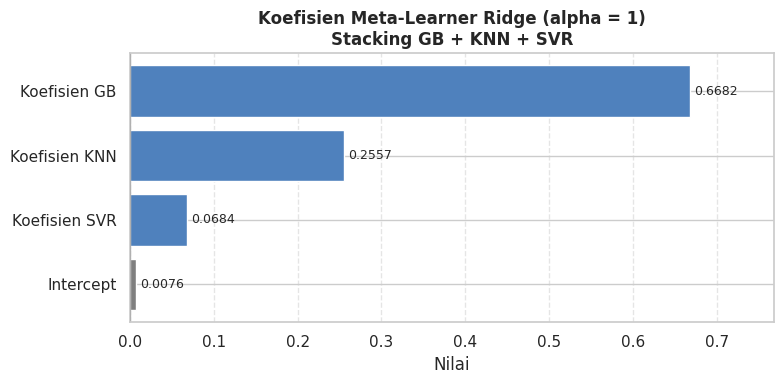

In [20]:
name = next(iter(stack_models))                      # 'Stacking GB + KNN + SVR'
stack = stack_models[name].regressor_
meta = stack.final_estimator_

df_meta = pd.DataFrame(
    [{'Komponen': f'Koefisien {LABEL[k]}', 'Nilai': c}
     for k, c in zip(stack.named_estimators_, meta.coef_)]
    + [{'Komponen': 'Intercept', 'Nilai': float(meta.intercept_)},
       {'Komponen': 'Alpha',     'Nilai': float(meta.alpha)}]
)
display(df_meta.round(4))

# visualisasi
plot_df = df_meta[df_meta['Komponen'] != 'Alpha'].copy()
is_coef = plot_df['Komponen'].str.startswith('Koefisien')
colors = np.where(~is_coef, '#7f7f7f',
                  np.where(plot_df['Nilai'] >= 0, '#4f81bd', '#c0504d'))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(plot_df['Komponen'], plot_df['Nilai'], color=colors, edgecolor='white')
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
ax.axvline(0, color='black', lw=0.8)
ax.invert_yaxis()
ax.set_xlabel('Nilai')
ax.set_title(f'Koefisien Meta-Learner Ridge (alpha = {meta.alpha:g})\n{name}',
             fontweight='bold')
ax.margins(x=0.15)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('koefisien_meta_learner.png', dpi=150, bbox_inches='tight')
plt.show()

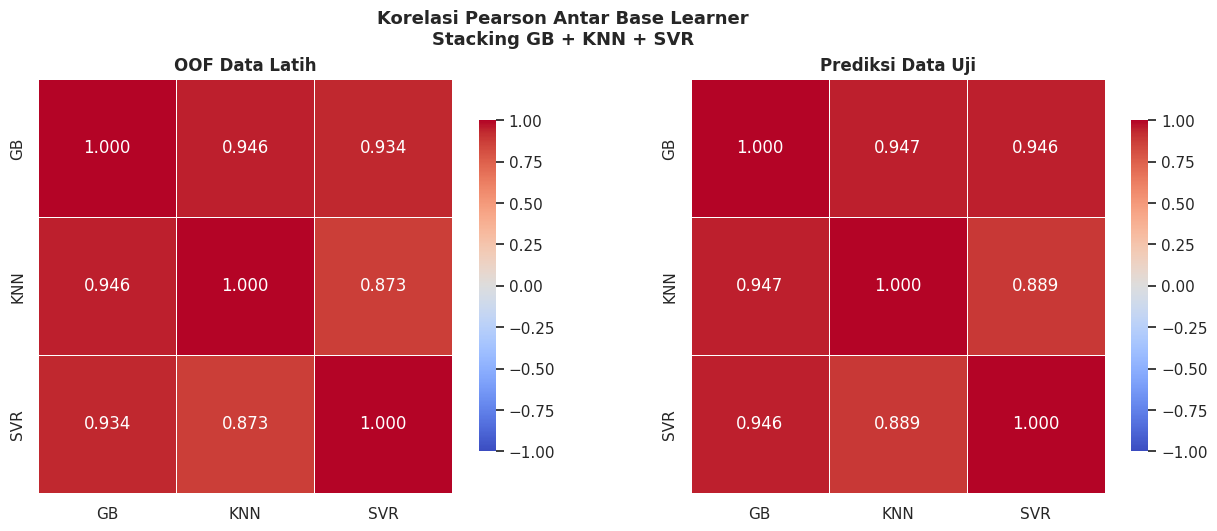

Korelasi OOF (latih):


,GB,KNN,SVR
GB,1.0000,0.9460,0.9342
KNN,0.9460,1.0000,0.8734
SVR,0.9342,0.8734,1.0000


Korelasi prediksi (uji):


,GB,KNN,SVR
GB,1.0000,0.9466,0.9458
KNN,0.9466,1.0000,0.8886
SVR,0.9458,0.8886,1.0000


In [21]:
# Matriks korelasi antar base learner
# (1) OOF data latih  -> yang dipakai meta-learner saat training
# (2) Prediksi data uji -> yang dipakai meta-learner saat inferensi
oof_cols = ['OOF_GB', 'OOF_KNN', 'OOF_SVR']

for name, model in stack_models.items():
    stack = model.regressor_

    # (1) OOF data latih
    oof_df = oof_tables[name][oof_cols]
    oof_df.columns = [c.replace('OOF_', '') for c in oof_df.columns]

    # (2) Prediksi base learner (hasil fit penuh) pada data uji, skala target ter-scaling
    test_df_bl = pd.DataFrame({
        LABEL[k]: est.predict(X_test)
        for k, est in stack.named_estimators_.items()
    })

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
    for ax, d, ttl in zip(axes, [oof_df, test_df_bl],
                          ['OOF Data Latih', 'Prediksi Data Uji']):
        corr = d.corr(method='pearson')
        sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm',
                    vmin=-1, vmax=1, linewidths=0.5, square=True,
                    cbar_kws={'shrink': 0.8}, ax=ax)
        ax.set_title(ttl, fontweight='bold')
    fig.suptitle(f'Korelasi Pearson Antar Base Learner\n{name}', fontsize=13, fontweight='bold')
    fig.savefig('korelasi_base_learner.png', dpi=150, bbox_inches='tight')
    plt.show()

    # tabel angka (opsional)
    print('Korelasi OOF (latih):')
    display(oof_df.corr().round(4))
    print('Korelasi prediksi (uji):')
    display(test_df_bl.corr().round(4))

## 8. Hasil Preprocessing di Dalam Model
Diambil dari pipeline model yang sudah di-fit pada data latih (scaler hanya belajar dari data latih; data uji hanya di-transform).

In [22]:
fitted = best_estimators['Gradient Boosting']
fitted_prep = fitted.regressor_.named_steps['prep'].named_transformers_['num']
fitted_y = fitted.transformer_


def pre_steps(X, y):
    xl = fitted_prep.named_steps['log'].transform(X)
    xs = fitted_prep.transform(X)
    yl = fitted_y.named_steps['log'].transform(y.to_frame())
    ys = fitted_y.transform(y.to_frame())
    return (pd.DataFrame(np.asarray(xl), columns=[f'{c}_log1p' for c in features]).assign(target_log1p=np.asarray(yl).ravel()),
            pd.DataFrame(xs, columns=[f'{c}_scaled' for c in features]).assign(target_scaled=np.asarray(ys).ravel()))


log_train, scaled_train = [pd.concat([ids_train, d], axis=1) for d in pre_steps(X_train, y_train)]
log_test, scaled_test = [pd.concat([ids_test, d], axis=1) for d in pre_steps(X_test, y_test)]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RobustScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RobustScaler was fitted without feature names
  warnings.warn(


### 8.1 Log1p

In [23]:
show("Log1p - data latih", log_train)
show("Log1p - data uji", log_test)


Log1p - data latih


,year,region,annual_palm_deforestation_(industrial)_hectares_log1p,oil_palm_planted_on_peat_hectares_log1p,oil_palm_planted_area_hectares_log1p,target_log1p
0,2015,ACEH BARAT,2.7542,7.3517,9.7622,10.1252
1,2015,ACEH BARAT DAYA,4.7618,4.5404,8.7532,11.2229
2,2015,ACEH JAYA,5.2565,0.0000,8.2001,11.8569
3,2015,ACEH SELATAN,0.0000,0.0000,7.9790,0.0000
4,2015,ACEH SINGKIL,5.1909,8.6021,10.5098,11.9361



Log1p - data uji


,year,region,annual_palm_deforestation_(industrial)_hectares_log1p,oil_palm_planted_on_peat_hectares_log1p,oil_palm_planted_area_hectares_log1p,target_log1p
0,2023,ACEH BARAT,1.6294,7.7091,9.9075,10.5245
1,2023,ACEH BARAT DAYA,5.2601,4.5404,8.8696,12.1475
2,2023,ACEH JAYA,0.0000,6.6227,8.6366,10.9026
3,2023,ACEH SELATAN,0.0000,0.0000,8.2176,11.7822
4,2023,ACEH SINGKIL,3.9092,8.6195,10.5419,11.5010


### 8.2 RobustScaler

In [24]:
show("RobustScaler - data latih", scaled_train)
show("RobustScaler - data uji", scaled_test)


RobustScaler - data latih


,year,region,annual_palm_deforestation_(industrial)_hectares_scaled,oil_palm_planted_on_peat_hectares_scaled,oil_palm_planted_area_hectares_scaled,target_scaled
0,2015,ACEH BARAT,0.6523,0.8560,-0.0462,0.0469
1,2015,ACEH BARAT DAYA,1.1278,0.5286,-0.4268,0.1369
2,2015,ACEH JAYA,1.2450,0.0000,-0.6354,0.1889
3,2015,ACEH SELATAN,0.0000,0.0000,-0.7188,-0.7833
4,2015,ACEH SINGKIL,1.2294,1.0015,0.2358,0.1954



RobustScaler - data uji


,year,region,annual_palm_deforestation_(industrial)_hectares_scaled,oil_palm_planted_on_peat_hectares_scaled,oil_palm_planted_area_hectares_scaled,target_scaled
0,2023,ACEH BARAT,0.3859,0.8976,0.0086,0.0796
1,2023,ACEH BARAT DAYA,1.2458,0.5286,-0.3829,0.2127
2,2023,ACEH JAYA,0.0000,0.7711,-0.4708,0.1106
3,2023,ACEH SELATAN,0.0000,0.0000,-0.6288,0.1828
4,2023,ACEH SINGKIL,0.9259,1.0036,0.2479,0.1597


### 8.3 Parameter RobustScaler

In [25]:
sx, sy = fitted_prep.named_steps['scaler'], fitted_y.named_steps['scaler']
scaler_params = pd.DataFrame({
    'variabel': features + [target],
    'median (center)': list(sx.center_) + list(sy.center_),
    'IQR (scale)': list(sx.scale_) + list(sy.scale_),
})
display(scaler_params.round(4))

,variabel,median (center),IQR (scale)
0,annual_palm_deforestation_(industrial)_hectares,0.0000,4.2222
1,oil_palm_planted_on_peat_hectares,0.0000,8.5888
2,oil_palm_planted_area_hectares,9.8847,2.6511
3,gross_emissions_from_land-use_change_tonnes_co...,9.5534,12.1958


### 8.4 Skewness Sebelum vs Sesudah Log1p (Data Latih)

In [26]:
log_vals = log_train.drop(columns=['year', 'region'])
log_vals.columns = num_cols

skew_tbl = pd.DataFrame({'sebelum': train_df[num_cols].skew(), 'sesudah': log_vals.skew()}).round(2)
display(skew_tbl)

,sebelum,sesudah
annual_palm_deforestation_(industrial)_hectares,9.55,0.91
oil_palm_planted_on_peat_hectares,3.36,0.58
oil_palm_planted_area_hectares,2.97,-1.76
gross_emissions_from_land-use_change_tonnes_co₂-equivalent,6.91,-0.24


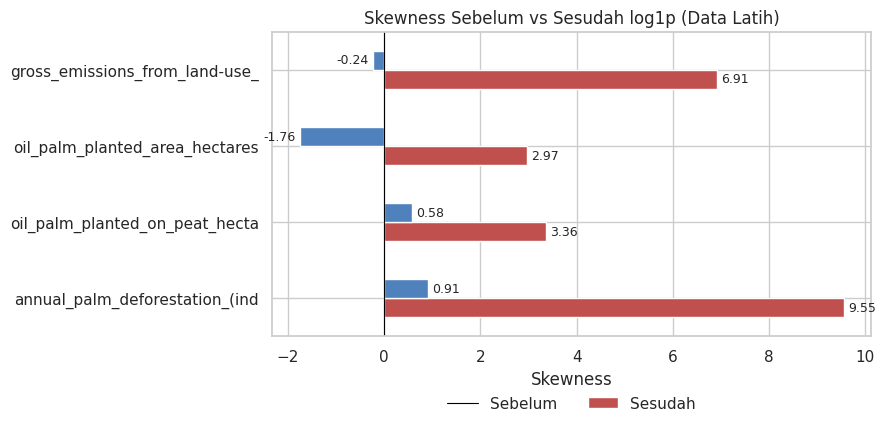

In [27]:
skew_plot = skew_tbl.copy()
skew_plot.index = [short(c) for c in skew_plot.index]
ax = skew_plot.plot(kind="barh", figsize=(9, 4.5), color=["#c0504d", "#4f81bd"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", padding=3, fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Skewness")
ax.set_title("Skewness Sebelum vs Sesudah log1p (Data Latih)")
ax.legend(["Sebelum", "Sesudah"], loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("skewness_sebelum_sesudah.png", dpi=150, bbox_inches="tight")
plt.show()

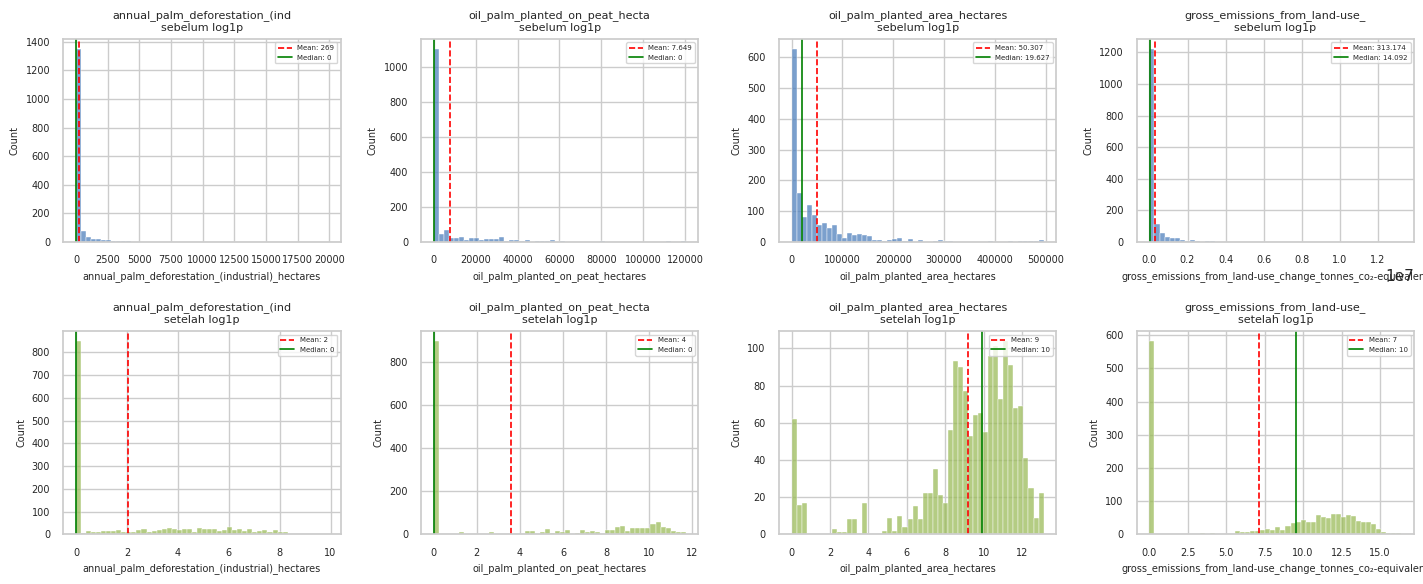

In [28]:
def fmt(x):
    return f"{x:,.0f}".replace(",", ".")

def plot_hist(ax, data, color, title, xlabel):
    sns.histplot(data, bins=50, ax=ax, color=color, edgecolor="white", linewidth=0.3)
    mean_v, med_v = data.mean(), data.median()
    ax.axvline(mean_v, color="red", linestyle="--", linewidth=1.2,
               label=f"Mean: {fmt(mean_v)}")
    ax.axvline(med_v, color="green", linestyle="-", linewidth=1.2,
               label=f"Median: {fmt(med_v)}")
    ax.set_title(title, fontsize=8)
    ax.set_xlabel(xlabel, fontsize=7)
    ax.set_ylabel("Count", fontsize=7)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=5, loc="upper right")

n = len(num_cols)
fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 6))

for j, c in enumerate(num_cols):
    # baris atas: sebelum log1p
    plot_hist(axes[0, j], train_df[c], "#4f81bd",
              f"{short(c)}\nsebelum log1p", c)
    # baris bawah: setelah log1p
    plot_hist(axes[1, j], log_vals[c], "#9bbb59",
              f"{short(c)}\nsetelah log1p", c)

plt.tight_layout()
plt.savefig("histogram_sebelum_sesudah_log1p.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.5 Simpan Hasil Preprocessing

In [29]:
def save_excel(path, sheets):
    with pd.ExcelWriter(path, engine='openpyxl') as writer:
        for sheet, data in sheets.items():
            data.to_excel(writer, sheet_name=sheet[:31], index=False)
            ws = writer.sheets[sheet[:31]]
            for col in ws.columns:
                width = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
                ws.column_dimensions[col[0].column_letter].width = min(width + 2, 45)


save_excel('hasil_preprocessing.xlsx', {
    'log1p_train': log_train,
    'log1p_test': log_test,
    'robustscaler_train': scaled_train,
    'robustscaler_test': scaled_test,
    'parameter_robustscaler': scaler_params,
})

## 9. Evaluasi

In [30]:
def metrics(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred), mean_absolute_error(y_true, y_pred), r2_score(y_true, y_pred)


preds_train = {n: m.predict(X_train) for n, m in all_models.items()}
preds_test = {n: m.predict(X_test) for n, m in all_models.items()}

rows = []
for n in all_models:
    tr, te = metrics(y_train, preds_train[n]), metrics(y_test, preds_test[n])
    rows.append({'Model': n,
                 'RMSE Train': tr[0], 'RMSE Test': te[0], 'Gap RMSE': te[0] - tr[0],
                 'MAE Train': tr[1], 'MAE Test': te[1], 'Gap MAE': te[1] - tr[1],
                 'R2 Train': tr[2], 'R2 Test': te[2], 'Gap R2': te[2] - tr[2]})

df_eval = pd.DataFrame(rows).sort_values('RMSE Test').reset_index(drop=True)
display(df_eval.style.format({c: '{:,.2f}' for c in df_eval.columns if c.startswith(('RMSE', 'MAE', 'Gap RMSE', 'Gap MAE'))}
                             | {c: '{:.4f}' for c in df_eval.columns if 'R2' in c}))

,Model,RMSE Train,RMSE Test,Gap RMSE,MAE Train,MAE Test,Gap MAE,R2 Train,R2 Test,Gap R2
0,Stacking GB + KNN + SVR,"404,243.28","308,103.98","-96,139.30","111,995.29","106,606.05","-5,389.24",0.8122,0.7578,-0.0544
1,Gradient Boosting,"441,413.26","318,582.83","-122,830.43","119,262.63","114,775.45","-4,487.19",0.7761,0.7411,-0.0350
2,KNN,"400,291.60","319,952.18","-80,339.42","100,750.11","113,760.50","13,010.39",0.8159,0.7388,-0.0770
3,SVR,"442,861.74","330,108.00","-112,753.74","146,498.72","123,286.57","-23,212.15",0.7746,0.7220,-0.0526


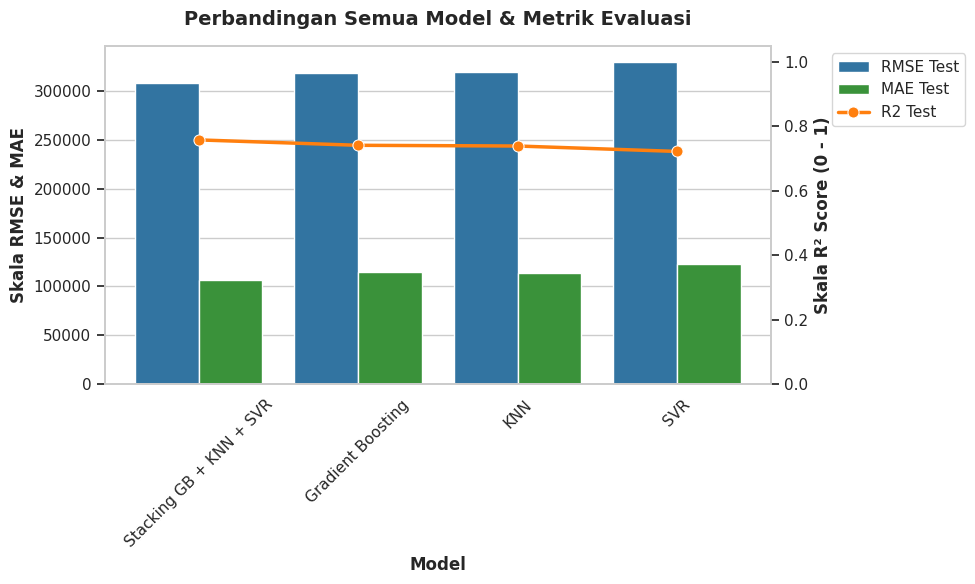

In [31]:
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

# rmse mae
df_cost = df_eval[['Model', 'RMSE Test', 'MAE Test']].melt(id_vars='Model', var_name='Metrik', value_name='Nilai')
sns.barplot(data=df_cost, x='Model', y='Nilai', hue='Metrik', ax=ax1, palette=['#1f77b4', '#2ca02c'])
ax1.set_ylabel('Skala RMSE & MAE', fontsize=12, fontweight='bold')
ax1.set_xlabel('Model', fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
if ax1.get_legend():
    ax1.get_legend().remove()

# r2
ax2 = ax1.twinx()
line_plot = sns.lineplot(data=df_eval, x='Model', y='R2 Test', ax=ax2, color='#ff7f0e', marker='o', linewidth=2.5, markersize=8, label='R2 Test')
ax2.set_ylabel('Skala R² Score (0 - 1)', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 1.05)
ax2.grid(False)
if ax2.get_legend():
    ax2.get_legend().remove()

# gabungin
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', bbox_to_anchor=(1.08, 1), frameon=True)
plt.title('Perbandingan Semua Model & Metrik Evaluasi', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [32]:
# invers
def inverse_steps(model, X, y_true):
    sy = model.transformer_.named_steps['scaler']

    # 1) keluaran regressor: skala RobustScaler
    pred_scaled = model.regressor_.predict(X)

    # 2) inverse RobustScaler: pred * IQR + median -> skala log1p
    pred_log1p = sy.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()

    # 3) expm1: kembali ke skala asli (tonnes CO2-eq)
    pred_asli = np.expm1(pred_log1p)

    assert np.allclose(pred_asli, model.predict(X)), "Hasil invers manual != model.predict()"

    # aktual dalam tiap skala (sebagai pembanding)
    y_log1p = np.log1p(y_true.values)
    y_scaled = sy.transform(y_log1p.reshape(-1, 1)).ravel()

    return pd.DataFrame({
        'Aktual (asli)'                  : y_true.values,    # data asli
        'Aktual (skala log1p)'           : y_log1p,          # log1p
        'Aktual (skala RobustScaler)'    : y_scaled,         # RobustScaler
        'Prediksi (skala RobustScaler)'  : pred_scaled,      # keluaran model
        'Prediksi (inverse RobustScaler)': pred_log1p,       # inverse RobustScaler -> skala log1p
        'Prediksi (expm1 / asli)'        : pred_asli,        # expm1 -> skala asli
    })


inverse_tables = {}
for name, model in all_models.items():
    tbl = inverse_steps(model, X_test, y_test)
    tbl.insert(0, 'region', ids_test['region'].values)
    tbl.insert(0, 'year', ids_test['year'].values)
    inverse_tables[name] = tbl

    print('=' * 100)
    print(f'MODEL: {name}  (data uji)')
    display(tbl.head(10).style.format({c: '{:,.4f}' for c in tbl.columns[2:]}))

save_excel('hasil_invers_prediksi.xlsx', {
    f"invers_{name.split(' (')[0]}"[:31]: tbl
    for name, tbl in inverse_tables.items()
})

MODEL: Gradient Boosting  (data uji)


,year,region,Aktual (asli),Aktual (skala log1p),Aktual (skala RobustScaler),Prediksi (skala RobustScaler),Prediksi (inverse RobustScaler),Prediksi (expm1 / asli)
0,2023,ACEH BARAT,"37,214.1520",10.5245,0.0796,0.0359,9.9907,"21,820.8238"
1,2023,ACEH BARAT DAYA,"188,624.3308",12.1475,0.2127,0.1693,11.6181,"111,091.5601"
2,2023,ACEH JAYA,"54,314.8910",10.9026,0.1106,-0.4520,4.0404,55.8488
3,2023,ACEH SELATAN,"130,906.5684",11.7822,0.1828,-0.7105,0.8887,1.4318
4,2023,ACEH SINGKIL,"98,811.8336",11.5010,0.1597,0.1435,11.3029,"81,055.1626"
5,2023,ACEH TAMIANG,"50,276.9306",10.8253,0.1043,0.1615,11.5230,"101,012.6305"
6,2023,ACEH TIMUR,"201,590.9109",12.2140,0.2182,0.0845,10.5834,"39,473.5759"
7,2023,ACEH UTARA,"454,580.7986",13.0271,0.2848,0.2870,13.0531,"466,525.7130"
8,2023,AGAM,0.0000,0.0000,-0.7833,-0.7307,0.6425,0.9012
9,2023,ASAHAN,"135,495.7284",11.8167,0.1856,-0.2917,5.9958,400.7210


MODEL: SVR  (data uji)


,year,region,Aktual (asli),Aktual (skala log1p),Aktual (skala RobustScaler),Prediksi (skala RobustScaler),Prediksi (inverse RobustScaler),Prediksi (expm1 / asli)
0,2023,ACEH BARAT,"37,214.1520",10.5245,0.0796,-0.1623,7.5744,"1,946.6299"
1,2023,ACEH BARAT DAYA,"188,624.3308",12.1475,0.2127,0.1715,11.6453,"114,157.8127"
2,2023,ACEH JAYA,"54,314.8910",10.9026,0.1106,-0.5013,3.4394,30.1681
3,2023,ACEH SELATAN,"130,906.5684",11.7822,0.1828,-0.6556,1.5581,3.7498
4,2023,ACEH SINGKIL,"98,811.8336",11.5010,0.1597,0.1289,11.1249,"67,837.2350"
5,2023,ACEH TAMIANG,"50,276.9306",10.8253,0.1043,0.0973,10.7397,"46,150.3972"
6,2023,ACEH TIMUR,"201,590.9109",12.2140,0.2182,-0.0791,8.5885,"5,368.4242"
7,2023,ACEH UTARA,"454,580.7986",13.0271,0.2848,0.3113,13.3497,"627,646.2886"
8,2023,AGAM,0.0000,0.0000,-0.7833,-0.3529,5.2501,189.5810
9,2023,ASAHAN,"135,495.7284",11.8167,0.1856,-0.1821,7.3328,"1,528.7137"


MODEL: KNN  (data uji)


,year,region,Aktual (asli),Aktual (skala log1p),Aktual (skala RobustScaler),Prediksi (skala RobustScaler),Prediksi (inverse RobustScaler),Prediksi (expm1 / asli)
0,2023,ACEH BARAT,"37,214.1520",10.5245,0.0796,0.1282,11.1170,"67,305.8890"
1,2023,ACEH BARAT DAYA,"188,624.3308",12.1475,0.2127,0.1655,11.5723,"106,117.8577"
2,2023,ACEH JAYA,"54,314.8910",10.9026,0.1106,-0.4672,3.8559,46.2723
3,2023,ACEH SELATAN,"130,906.5684",11.7822,0.1828,-0.7833,0.0000,0.0000
4,2023,ACEH SINGKIL,"98,811.8336",11.5010,0.1597,0.1033,10.8130,"49,662.3620"
5,2023,ACEH TAMIANG,"50,276.9306",10.8253,0.1043,0.1770,11.7124,"122,076.7574"
6,2023,ACEH TIMUR,"201,590.9109",12.2140,0.2182,0.0961,10.7251,"45,483.4409"
7,2023,ACEH UTARA,"454,580.7986",13.0271,0.2848,0.2751,12.9081,"403,580.5170"
8,2023,AGAM,0.0000,0.0000,-0.7833,-0.7833,0.0000,0.0000
9,2023,ASAHAN,"135,495.7284",11.8167,0.1856,-0.2017,7.0938,"1,203.5171"


MODEL: Stacking GB + KNN + SVR  (data uji)


,year,region,Aktual (asli),Aktual (skala log1p),Aktual (skala RobustScaler),Prediksi (skala RobustScaler),Prediksi (inverse RobustScaler),Prediksi (expm1 / asli)
0,2023,ACEH BARAT,"37,214.1520",10.5245,0.0796,0.0533,10.2032,"26,988.2205"
1,2023,ACEH BARAT DAYA,"188,624.3308",12.1475,0.2127,0.1748,11.6857,"118,854.1467"
2,2023,ACEH JAYA,"54,314.8910",10.9026,0.1106,-0.4482,4.0876,58.5991
3,2023,ACEH SELATAN,"130,906.5684",11.7822,0.1828,-0.7122,0.8670,1.3797
4,2023,ACEH SINGKIL,"98,811.8336",11.5010,0.1597,0.1387,11.2453,"76,514.9679"
5,2023,ACEH TAMIANG,"50,276.9306",10.8253,0.1043,0.1675,11.5960,"108,655.9217"
6,2023,ACEH TIMUR,"201,590.9109",12.2140,0.2182,0.0832,10.5684,"38,886.9990"
7,2023,ACEH UTARA,"454,580.7986",13.0271,0.2848,0.2910,13.1027,"490,258.4458"
8,2023,AGAM,0.0000,0.0000,-0.7833,-0.7050,0.9552,1.5991
9,2023,ASAHAN,"135,495.7284",11.8167,0.1856,-0.2513,6.4886,656.6119


## 10. Prediksi Stacking dan Aktual vs Prediksi (Data Uji)

In [33]:
X_test_view = X_test.reset_index(drop=True)
df_actual_pred = pd.concat([ids_test.reset_index(drop=True), X_test_view,
                            pd.DataFrame({'Aktual': y_test.values})], axis=1)
for n in all_models:
    df_actual_pred[n] = preds_test[n]

df_stack_pred = df_actual_pred[['year', 'region'] + list(features) + ['Aktual'] + list(stack_models)].copy()
for n in stack_models:
    df_stack_pred[f'Selisih {n}'] = df_stack_pred[n] - df_stack_pred['Aktual']


def tampil(title, d, n=10):
    print(f'\n{title}')
    num_cols_fmt = [c for c in d.select_dtypes('number').columns if c != 'year']
    display(d.head(n).style.format({c: '{:,.2f}' for c in num_cols_fmt}))


tampil("Prediksi Stacking (Selisih = Prediksi - Aktual)", df_stack_pred)
tampil("Aktual vs Prediksi Semua Model", df_actual_pred)


Prediksi Stacking (Selisih = Prediksi - Aktual)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Stacking GB + KNN + SVR,Selisih Stacking GB + KNN + SVR
0,2023,ACEH BARAT,4.10,"2,227.59","20,079.91","37,214.15","26,988.22","-10,225.93"
1,2023,ACEH BARAT DAYA,191.51,92.72,"7,111.49","188,624.33","118,854.15","-69,770.18"
2,2023,ACEH JAYA,0.00,751.00,"5,632.90","54,314.89",58.60,"-54,256.29"
3,2023,ACEH SELATAN,0.00,0.00,"3,704.51","130,906.57",1.38,"-130,905.19"
4,2023,ACEH SINGKIL,48.86,"5,537.82","37,866.57","98,811.83","76,514.97","-22,296.87"
5,2023,ACEH TAMIANG,53.66,0.00,"44,977.96","50,276.93","108,655.92","58,378.99"
6,2023,ACEH TIMUR,12.65,0.00,"37,346.20","201,590.91","38,887.00","-162,703.91"
7,2023,ACEH UTARA,651.95,0.00,"17,919.13","454,580.80","490,258.45","35,677.65"
8,2023,AGAM,0.00,"7,068.34","17,558.98",0.00,1.60,1.60
9,2023,ASAHAN,0.00,"6,007.93","89,181.36","135,495.73",656.61,"-134,839.12"



Aktual vs Prediksi Semua Model


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Gradient Boosting,SVR,KNN,Stacking GB + KNN + SVR
0,2023,ACEH BARAT,4.10,"2,227.59","20,079.91","37,214.15","21,820.82","1,946.63","67,305.89","26,988.22"
1,2023,ACEH BARAT DAYA,191.51,92.72,"7,111.49","188,624.33","111,091.56","114,157.81","106,117.86","118,854.15"
2,2023,ACEH JAYA,0.00,751.00,"5,632.90","54,314.89",55.85,30.17,46.27,58.60
3,2023,ACEH SELATAN,0.00,0.00,"3,704.51","130,906.57",1.43,3.75,0.00,1.38
4,2023,ACEH SINGKIL,48.86,"5,537.82","37,866.57","98,811.83","81,055.16","67,837.23","49,662.36","76,514.97"
5,2023,ACEH TAMIANG,53.66,0.00,"44,977.96","50,276.93","101,012.63","46,150.40","122,076.76","108,655.92"
6,2023,ACEH TIMUR,12.65,0.00,"37,346.20","201,590.91","39,473.58","5,368.42","45,483.44","38,887.00"
7,2023,ACEH UTARA,651.95,0.00,"17,919.13","454,580.80","466,525.71","627,646.29","403,580.52","490,258.45"
8,2023,AGAM,0.00,"7,068.34","17,558.98",0.00,0.90,189.58,0.00,1.60
9,2023,ASAHAN,0.00,"6,007.93","89,181.36","135,495.73",400.72,"1,528.71","1,203.52",656.61


In [34]:
def time_inference(model, X, n_repeat=30):
    model.predict(X)
    t = []
    for _ in range(n_repeat):
        t0 = time.perf_counter()
        model.predict(X)
        t.append(time.perf_counter() - t0)
    return np.median(t), np.std(t)

tuning_info = df_tuning.set_index('Model')

rows = []
for n, m in all_models.items():
    med, std = time_inference(m, X_test)
    if n in stack_models:
        t_tune = tuning_info.loc[[k for _, k in stack_configs[n]], 'Waktu Tuning (s)'].sum()  # tuning base learner
        t_fit = stack_fit_time[n]
    else:
        t_tune = tuning_info.loc[n, 'Waktu Tuning (s)']
        t_fit = tuning_info.loc[n, 'Waktu Fit Final (s)']
    rows.append({
        'Model': n,
        'Waktu Tuning (s)': t_tune,
        'Waktu Fit Final (s)': t_fit,
        'Total Komputasi (s)': t_tune + t_fit,
        f'Inferensi {len(X_test)} baris (ms)': med * 1000,
        'Std Inferensi (ms)': std * 1000,
        'Inferensi per sampel (ms)': med * 1000 / len(X_test),
    })

df_time = pd.DataFrame(rows).sort_values('Total Komputasi (s)').reset_index(drop=True)
display(df_time.round(4))

,Model,Waktu Tuning (s),Waktu Fit Final (s),Total Komputasi (s),Inferensi 390 baris (ms),Std Inferensi (ms),Inferensi per sampel (ms)
0,KNN,1.7525,0.0106,1.7631,5.2769,0.2672,0.0135
1,SVR,21.3011,0.1082,21.4094,28.4867,3.0713,0.0730
2,Gradient Boosting,35.1994,0.4007,35.6002,5.8887,0.6824,0.0151
3,Stacking GB + KNN + SVR,58.2530,1.6801,59.9331,39.5933,2.9994,0.1015


In [35]:
def best_worst_samples(test_df, y_true, y_pred, features, target, n=10, only_positive=False):
    d = test_df[['year', 'region'] + features].copy()
    d['Aktual'] = y_true.values
    d['Prediksi'] = y_pred
    d['Selisih'] = d['Prediksi'] - d['Aktual']
    d['Abs Error'] = d['Selisih'].abs()

    pool = d[d['Aktual'] > 0] if only_positive else d
    best = pool.nsmallest(n, 'Abs Error').reset_index(drop=True)    # paling mendekati
    worst = pool.nlargest(n, 'Abs Error').reset_index(drop=True)    # paling sulit diprediksi
    return best, worst


def show_samples(title, d):
    cols_fmt = {c: '{:,.2f}' for c in d.select_dtypes('number').columns if c != 'year'}
    print(f'\n{title}')
    display(d.style.format(cols_fmt))

ONLY_POSITIVE = False

best_worst = {}
for name in all_models:
    best, worst = best_worst_samples(test_df, y_test, preds_test[name],
                                     features, target, n=10, only_positive=ONLY_POSITIVE)
    best_worst[name] = (best, worst)

    print('=' * 100)
    print(f'MODEL: {name}')
    show_samples('10 sampel PALING MENDEKATI (error terkecil)', best)
    show_samples('10 sampel PALING JAUH / SULIT DIPREDIKSI (error terbesar)', worst)

MODEL: Gradient Boosting

10 sampel PALING MENDEKATI (error terkecil)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2023,SARMI,0.00,12.35,28.88,0.00,0.31,0.31,0.31
1,2024,SARMI,0.00,12.35,28.88,0.00,0.31,0.31,0.31
2,2023,CIANJUR,0.00,0.00,691.82,0.00,0.46,0.46,0.46
3,2023,MIMIKA,0.00,0.00,981.14,0.00,0.46,0.46,0.46
4,2023,PESAWARAN,0.00,0.00,"1,064.20",0.00,0.46,0.46,0.46
5,2023,SUBANG,0.00,0.00,942.53,0.00,0.46,0.46,0.46
6,2023,WAJO,0.00,0.00,787.24,0.00,0.46,0.46,0.46
7,2024,CIANJUR,0.00,0.00,691.82,0.00,0.46,0.46,0.46
8,2024,MIMIKA,0.00,0.00,981.14,0.00,0.46,0.46,0.46
9,2024,PESAWARAN,0.00,0.00,"1,064.20",0.00,0.46,0.46,0.46



10 sampel PALING JAUH / SULIT DIPREDIKSI (error terbesar)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2024,KUTAI BARAT,"1,745.04",177.72,"191,360.55","4,790,491.33","1,909,343.77","-2,881,147.56","2,881,147.56"
1,2024,KUTAI TIMUR,16.51,14.35,"476,179.09","2,901,796.37","400,570.71","-2,501,225.65","2,501,225.65"
2,2023,KUTAI BARAT,"1,512.74",177.72,"186,429.75","3,968,093.12","1,977,471.71","-1,990,621.41","1,990,621.41"
3,2023,KUTAI TIMUR,1.43,14.35,"473,354.63","2,162,711.09","202,374.34","-1,960,336.75","1,960,336.75"
4,2024,MUSI BANYUASIN,24.46,"62,271.55","262,398.72","1,541,815.25","297,252.40","-1,244,562.85","1,244,562.85"
5,2023,MUSI RAWAS UTARA,2.68,"20,026.66","73,265.59","1,170,818.24","63,410.75","-1,107,407.49","1,107,407.49"
6,2024,KAPUAS HULU,"4,350.57","9,688.97","91,156.96","3,323,893.28","4,372,391.41","1,048,498.13","1,048,498.13"
7,2023,MUSI BANYUASIN,196.90,"62,209.36","259,692.57","1,605,485.08","590,063.75","-1,015,421.33","1,015,421.33"
8,2024,GUNUNG MAS,384.67,0.00,"73,669.44","1,378,146.30","438,301.73","-939,844.58","939,844.58"
9,2023,MUSI RAWAS,0.00,397.33,"66,412.01","940,237.36","3,715.46","-936,521.90","936,521.90"


MODEL: SVR

10 sampel PALING MENDEKATI (error terkecil)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2023,BENER MERIAH,0.00,0.00,572.24,0.00,0.00,0.00,0.00
1,2024,SAMOSIR,0.00,0.00,0.78,0.00,-0.01,-0.01,0.01
2,2023,SERAM BAGIAN TIMUR,0.00,0.00,0.82,0.00,-0.01,-0.01,0.01
3,2024,SERAM BAGIAN TIMUR,0.00,0.00,0.82,0.00,-0.01,-0.01,0.01
4,2023,KOTA BALIKPAPAN,0.00,0.00,588.42,0.00,0.02,0.02,0.02
5,2024,KOTA BALIKPAPAN,0.00,0.00,588.42,0.00,0.02,0.02,0.02
6,2023,KOTA TANJUNG PINANG,0.00,0.00,0.90,0.00,-0.03,-0.03,0.03
7,2024,KOTA TANJUNG PINANG,0.00,0.00,0.90,0.00,-0.03,-0.03,0.03
8,2023,LAMPUNG TIMUR,0.00,0.00,0.64,0.00,0.03,0.03,0.03
9,2024,LAMPUNG TIMUR,0.00,0.00,0.64,0.00,0.03,0.03,0.03


... (6 outputs left out)

MODEL: Stacking GB + KNN + SVR

10 sampel PALING MENDEKATI (error terkecil)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2023,SARMI,0.00,12.35,28.88,0.00,0.39,0.39,0.39
1,2024,SARMI,0.00,12.35,28.88,0.00,0.39,0.39,0.39
2,2023,KOTA MEDAN,0.00,0.00,46.66,0.00,0.51,0.51,0.51
3,2024,KOTA MEDAN,0.00,0.00,46.66,0.00,0.51,0.51,0.51
4,2023,KOTA BINJAI,0.00,0.00,48.36,0.00,0.51,0.51,0.51
5,2024,KOTA BINJAI,0.00,0.00,48.36,0.00,0.51,0.51,0.51
6,2023,CIANJUR,0.00,0.00,691.82,0.00,0.53,0.53,0.53
7,2024,CIANJUR,0.00,0.00,691.82,0.00,0.53,0.53,0.53
8,2023,WAJO,0.00,0.00,787.24,0.00,0.54,0.54,0.54
9,2024,WAJO,0.00,0.00,787.24,0.00,0.54,0.54,0.54



10 sampel PALING JAUH / SULIT DIPREDIKSI (error terbesar)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2024,KUTAI BARAT,"1,745.04",177.72,"191,360.55","4,790,491.33","2,045,321.97","-2,745,169.36","2,745,169.36"
1,2024,KUTAI TIMUR,16.51,14.35,"476,179.09","2,901,796.37","355,144.04","-2,546,652.33","2,546,652.33"
2,2023,KUTAI TIMUR,1.43,14.35,"473,354.63","2,162,711.09","229,624.51","-1,933,086.58","1,933,086.58"
3,2023,KUTAI BARAT,"1,512.74",177.72,"186,429.75","3,968,093.12","2,083,111.79","-1,884,981.32","1,884,981.32"
4,2024,MUSI BANYUASIN,24.46,"62,271.55","262,398.72","1,541,815.25","287,332.16","-1,254,483.09","1,254,483.09"
5,2024,KOTABARU,"2,037.07",0.00,"190,876.64","1,027,515.81","2,210,169.47","1,182,653.66","1,182,653.66"
6,2023,MUSI RAWAS UTARA,2.68,"20,026.66","73,265.59","1,170,818.24","78,580.85","-1,092,237.40","1,092,237.40"
7,2023,MUSI BANYUASIN,196.90,"62,209.36","259,692.57","1,605,485.08","563,499.11","-1,041,985.97","1,041,985.97"
8,2023,MUSI RAWAS,0.00,397.33,"66,412.01","940,237.36","14,920.77","-925,316.58","925,316.58"
9,2024,MUSI RAWAS,0.00,401.38,"70,255.86","859,861.54","16,790.15","-843,071.39","843,071.39"


In [36]:
def best_worst_positive(test_df, y_true, y_pred, features, n=10):
    d = test_df[['year', 'region'] + features].copy()
    d['Aktual'] = y_true.values
    d['Prediksi'] = y_pred
    d['Selisih'] = d['Prediksi'] - d['Aktual']
    d['Abs Error'] = d['Selisih'].abs()

    d = d[d['Aktual'] > 0]                                   # hanya target positif
    best = d.nsmallest(n, 'Abs Error').reset_index(drop=True)   # paling mendekati
    worst = d.nlargest(n, 'Abs Error').reset_index(drop=True)   # paling sulit diprediksi
    return best, worst


def show_samples(title, d):
    cols_fmt = {c: '{:,.2f}' for c in d.select_dtypes('number').columns if c != 'year'}
    print(f'\n{title}')
    display(d.style.format(cols_fmt))


n_pos = int((y_test > 0).sum())
print(f'Baris uji dengan target aktual > 0: {n_pos} dari {len(y_test)}')

best_worst = {}
for name in all_models:
    best, worst = best_worst_positive(test_df, y_test, preds_test[name], features, n=10)
    best_worst[name] = (best, worst)

    print('=' * 100)
    print(f'MODEL: {name}')
    show_samples('10 sampel PALING MENDEKATI (error terkecil, target > 0)', best)
    show_samples('10 sampel PALING JAUH / SULIT DIPREDIKSI (error terbesar, target > 0)', worst)

Baris uji dengan target aktual > 0: 220 dari 390
MODEL: Gradient Boosting

10 sampel PALING MENDEKATI (error terkecil, target > 0)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2024,SIMALUNGUN,0.00,0.00,"81,508.27",17.22,49.72,32.51,32.51
1,2023,OGAN KOMERING ULU,0.00,0.00,"34,526.36",58.25,9.37,-48.88,48.88
2,2024,PULANG PISAU,73.42,"76,772.48","104,575.36","119,651.09","119,380.03",-271.06,271.06
3,2023,WAY KANAN,0.00,0.00,"10,277.31",287.62,7.08,-280.54,280.54
4,2023,SAROLANGUN,0.00,"23,588.63","53,636.65","3,902.05","3,600.77",-301.28,301.28
5,2024,SELUMA,1.43,0.00,"11,039.85","1,656.47","3,104.08","1,447.61","1,447.61"
6,2023,KOTA LUBUK LINGGAU,0.00,0.00,204.65,"1,634.61",5.29,"-1,629.33","1,629.33"
7,2023,BIREUEN,0.00,0.00,"5,814.89","1,763.42",54.57,"-1,708.85","1,708.85"
8,2023,MUKO MUKO,0.98,0.01,"46,170.50","1,672.75","3,553.18","1,880.43","1,880.43"
9,2024,LABUHANBATU,0.00,"56,829.80","89,936.52","2,166.73",26.05,"-2,140.69","2,140.69"



10 sampel PALING JAUH / SULIT DIPREDIKSI (error terbesar, target > 0)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2024,KUTAI BARAT,"1,745.04",177.72,"191,360.55","4,790,491.33","1,909,343.77","-2,881,147.56","2,881,147.56"
1,2024,KUTAI TIMUR,16.51,14.35,"476,179.09","2,901,796.37","400,570.71","-2,501,225.65","2,501,225.65"
2,2023,KUTAI BARAT,"1,512.74",177.72,"186,429.75","3,968,093.12","1,977,471.71","-1,990,621.41","1,990,621.41"
3,2023,KUTAI TIMUR,1.43,14.35,"473,354.63","2,162,711.09","202,374.34","-1,960,336.75","1,960,336.75"
4,2024,MUSI BANYUASIN,24.46,"62,271.55","262,398.72","1,541,815.25","297,252.40","-1,244,562.85","1,244,562.85"
5,2023,MUSI RAWAS UTARA,2.68,"20,026.66","73,265.59","1,170,818.24","63,410.75","-1,107,407.49","1,107,407.49"
6,2024,KAPUAS HULU,"4,350.57","9,688.97","91,156.96","3,323,893.28","4,372,391.41","1,048,498.13","1,048,498.13"
7,2023,MUSI BANYUASIN,196.90,"62,209.36","259,692.57","1,605,485.08","590,063.75","-1,015,421.33","1,015,421.33"
8,2024,GUNUNG MAS,384.67,0.00,"73,669.44","1,378,146.30","438,301.73","-939,844.58","939,844.58"
9,2023,MUSI RAWAS,0.00,397.33,"66,412.01","940,237.36","3,715.46","-936,521.90","936,521.90"


MODEL: SVR

10 sampel PALING MENDEKATI (error terkecil, target > 0)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2023,OGAN KOMERING ULU,0.00,0.00,"34,526.36",58.25,75.72,17.47,17.47
1,2024,LABUHANBATU,0.00,"56,829.80","89,936.52","2,166.73","2,230.08",63.34,63.34
2,2024,SIMALUNGUN,0.00,0.00,"81,508.27",17.22,263.25,246.04,246.04
3,2023,WAY KANAN,0.00,0.00,"10,277.31",287.62,14.31,-273.31,273.31
4,2023,KOTA PALANGKARAYA,507.68,0.00,"5,268.10","298,824.95","299,436.98",612.02,612.02
5,2024,KUANTAN SINGINGI,1.46,0.00,"111,154.01","2,574.57","1,534.39","-1,040.17","1,040.17"
6,2023,MUKO MUKO,0.98,0.01,"46,170.50","1,672.75",343.57,"-1,329.18","1,329.18"
7,2023,BUOL,108.07,0.00,"23,898.05","73,625.30","74,962.67","1,337.37","1,337.37"
8,2024,SELUMA,1.43,0.00,"11,039.85","1,656.47",80.41,"-1,576.06","1,576.06"
9,2023,KOTA LUBUK LINGGAU,0.00,0.00,204.65,"1,634.61",-0.39,"-1,635.00","1,635.00"


... (6 outputs left out)

MODEL: Stacking GB + KNN + SVR

10 sampel PALING MENDEKATI (error terkecil, target > 0)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2024,KOTA PALANGKARAYA,113.67,0.00,"6,183.74","124,896.90","124,902.94",6.04,6.04
1,2023,OGAN KOMERING ULU,0.00,0.00,"34,526.36",58.25,6.59,-51.66,51.66
2,2024,SIMALUNGUN,0.00,0.00,"81,508.27",17.22,104.50,87.28,87.28
3,2023,WAY KANAN,0.00,0.00,"10,277.31",287.62,20.65,-266.97,266.97
4,2023,BANJAR,5.18,"2,200.83","25,322.56","23,454.14","23,825.15",371.01,371.01
5,2023,SAROLANGUN,0.00,"23,588.63","53,636.65","3,902.05","3,435.41",-466.64,466.64
6,2024,BIREUEN,3.30,0.00,"5,827.34","14,668.89","15,273.17",604.28,604.28
7,2023,MAYBRAT,3.31,0.00,"4,702.73","3,461.93","4,174.85",712.92,712.92
8,2024,SELUMA,1.43,0.00,"11,039.85","1,656.47","3,012.16","1,355.69","1,355.69"
9,2023,MUKO MUKO,0.98,0.01,"46,170.50","1,672.75","3,039.41","1,366.66","1,366.66"



10 sampel PALING JAUH / SULIT DIPREDIKSI (error terbesar, target > 0)


,year,region,annual_palm_deforestation_(industrial)_hectares,oil_palm_planted_on_peat_hectares,oil_palm_planted_area_hectares,Aktual,Prediksi,Selisih,Abs Error
0,2024,KUTAI BARAT,"1,745.04",177.72,"191,360.55","4,790,491.33","2,045,321.97","-2,745,169.36","2,745,169.36"
1,2024,KUTAI TIMUR,16.51,14.35,"476,179.09","2,901,796.37","355,144.04","-2,546,652.33","2,546,652.33"
2,2023,KUTAI TIMUR,1.43,14.35,"473,354.63","2,162,711.09","229,624.51","-1,933,086.58","1,933,086.58"
3,2023,KUTAI BARAT,"1,512.74",177.72,"186,429.75","3,968,093.12","2,083,111.79","-1,884,981.32","1,884,981.32"
4,2024,MUSI BANYUASIN,24.46,"62,271.55","262,398.72","1,541,815.25","287,332.16","-1,254,483.09","1,254,483.09"
5,2024,KOTABARU,"2,037.07",0.00,"190,876.64","1,027,515.81","2,210,169.47","1,182,653.66","1,182,653.66"
6,2023,MUSI RAWAS UTARA,2.68,"20,026.66","73,265.59","1,170,818.24","78,580.85","-1,092,237.40","1,092,237.40"
7,2023,MUSI BANYUASIN,196.90,"62,209.36","259,692.57","1,605,485.08","563,499.11","-1,041,985.97","1,041,985.97"
8,2023,MUSI RAWAS,0.00,397.33,"66,412.01","940,237.36","14,920.77","-925,316.58","925,316.58"
9,2024,MUSI RAWAS,0.00,401.38,"70,255.86","859,861.54","16,790.15","-843,071.39","843,071.39"


In [37]:
from scipy.stats import wilcoxon

STACK = next(iter(stack_models))
BASES = [n for n in all_models if n not in stack_models]

err = test_df[['year', 'region']].copy()
err['Aktual'] = y_test.values
for n in all_models:
    err[f'AE_{n}'] = (preds_test[n] - y_test.values).__abs__()

RMSE per tahun (data uji)


,Gradient Boosting,SVR,KNN,Stacking GB + KNN + SVR
year,,,,
2023,276878.36,280701.62,276375.08,266327.16
2024,355427.08,373027.06,358267.51,344856.45



RMSE berdasarkan kelompok target


,Gradient Boosting,SVR,KNN,Stacking GB + KNN + SVR,Jumlah baris
Kelompok,,,,,
Target = 0,1750.43,465.29,12923.20,1363.85,170
Target > 0,424170.50,439518.16,425845.01,410219.61,220


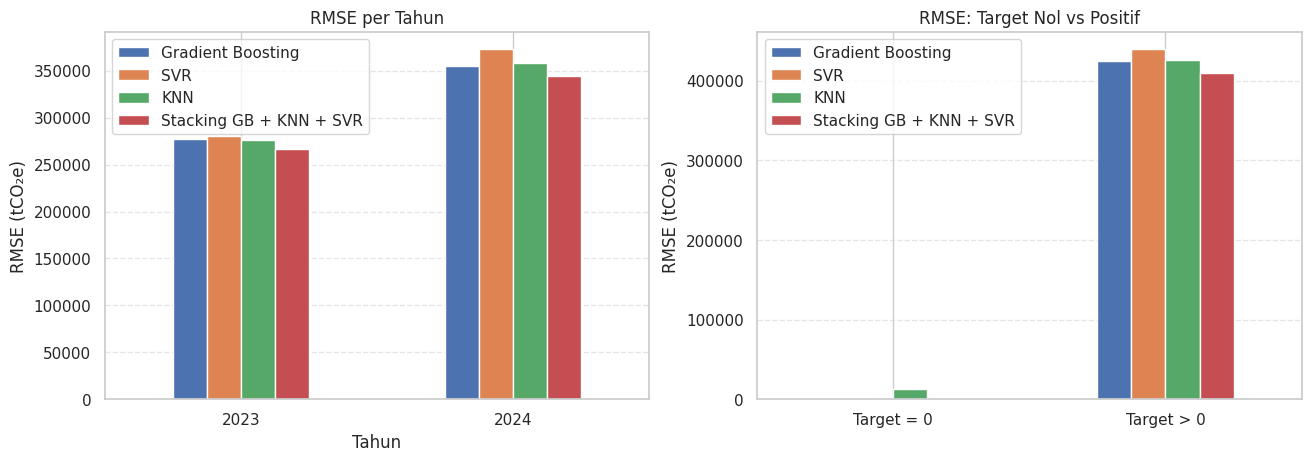

In [38]:
# kuadrat error per baris (RMSE = akar dari rata-rata kuadrat error)
for n in all_models:
    err[f'SE_{n}'] = (preds_test[n] - y_test.values) ** 2

se_cols = [f'SE_{n}' for n in all_models]
model_names = list(all_models)

# per tahun
per_year = np.sqrt(err.groupby('year')[se_cols].mean())
per_year.columns = model_names
print('RMSE per tahun (data uji)')
display(per_year.round(2))

# target nol vs positif
err['Kelompok'] = np.where(err['Aktual'] > 0, 'Target > 0', 'Target = 0')
per_grp = np.sqrt(err.groupby('Kelompok')[se_cols].mean())
per_grp.columns = model_names
per_grp['Jumlah baris'] = err.groupby('Kelompok').size()
print('\nRMSE berdasarkan kelompok target')
display(per_grp.round(2))

# visualisasi
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
per_year.plot(kind='bar', ax=axes[0], rot=0, edgecolor='white')
axes[0].set(title='RMSE per Tahun', xlabel='Tahun', ylabel='RMSE (tCO₂e)')
per_grp.drop(columns='Jumlah baris').plot(kind='bar', ax=axes[1], rot=0, edgecolor='white')
axes[1].set(title='RMSE: Target Nol vs Positif', xlabel='', ylabel='RMSE (tCO₂e)')
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig('error_per_tahun_kelompok.png', dpi=150, bbox_inches='tight')
plt.show()

10 kabupaten dengan MAE stacking terbesar


,Gradient Boosting,SVR,KNN,Stacking GB + KNN + SVR,Rata2 Aktual
region,,,,,
KUTAI BARAT,"2,435,884.49","1,932,403.82","2,516,083.82","2,315,075.34","4,379,292.23"
KUTAI TIMUR,"2,230,781.20","2,461,290.25","2,153,907.61","2,239,869.45","2,532,253.73"
MUSI BANYUASIN,"1,129,992.09","1,189,340.85","1,267,047.37","1,148,234.53","1,573,650.16"
MUSI RAWAS UTARA,"903,029.69","950,829.70","766,813.22","885,879.93","959,686.84"
MUSI RAWAS,"895,993.06","899,397.22","40,187.91","884,193.99","900,049.45"
KOTABARU,"667,074.89","1,285,214.51","1,153,558.62","721,404.38","3,615,254.61"
GUNUNG MAS,"758,532.73","412,870.10","658,009.80","674,464.76","1,394,316.31"
OGAN KOMERING ILIR,"555,697.05","570,411.12","153,078.31","527,007.20","578,320.90"
KAPUAS,"515,488.23","204,666.55","698,287.24","506,373.42","1,162,179.10"


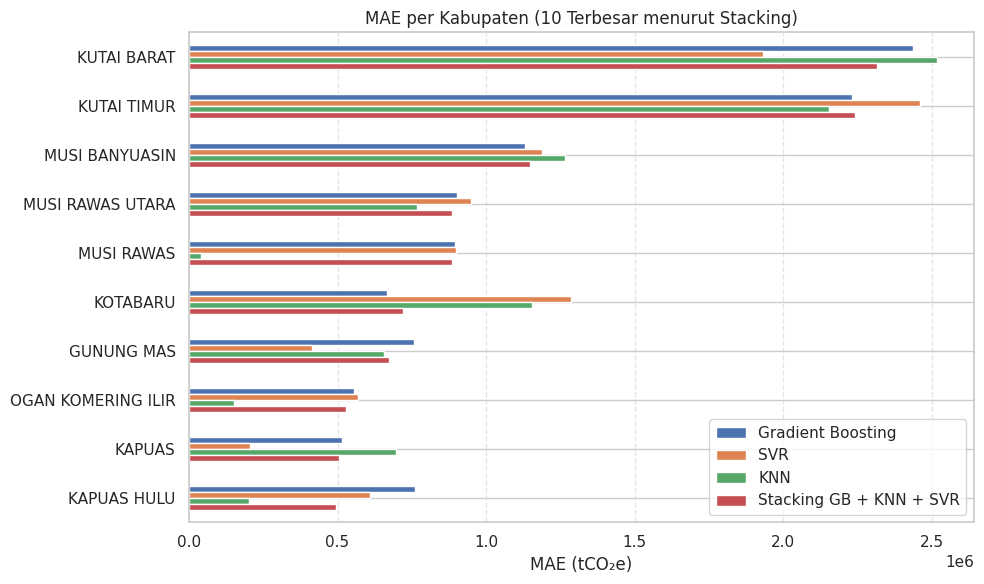

In [39]:
# error per kab

ae_cols = [f'AE_{n}' for n in all_models]
per_region = err.groupby('region')[ae_cols].mean()
per_region.columns = list(all_models)
per_region['Rata2 Aktual'] = err.groupby('region')['Aktual'].mean()
top = per_region.sort_values(STACK, ascending=False).head(10)

print('10 kabupaten dengan MAE stacking terbesar')
display(top.style.format('{:,.2f}'))

ax = top[list(all_models)].plot(kind='barh', figsize=(10, 6), edgecolor='white')
ax.invert_yaxis()
ax.set(title='MAE per Kabupaten (10 Terbesar menurut Stacking)', xlabel='MAE (tCO₂e)', ylabel='')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('error_per_kabupaten.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Simpan Hasil Stacking ke Excel

In [40]:
save_excel('hasil_stacking.xlsx', {
    **{f"OOF {n.split(' (')[0]}": t for n, t in oof_tables.items()},
    'koefisien_meta_learner': df_meta,
    'evaluasi_model': df_eval,
    'waktu_komputasi_inferensi': df_time
})

save_excel('hasil_aktual_vs_prediksi.xlsx', {
    'prediksi_stacking': df_stack_pred,
    'aktual_vs_prediksi': df_actual_pred,
})

sheets = {}
for name, (best, worst) in best_worst.items():
    short_name = name.replace('Stacking GB + KNN + SVR', 'Stacking')[:20]
    sheets[f'{short_name}_terdekat'] = best
    sheets[f'{short_name}_tersulit'] = worst
save_excel('hasil_sampel_terbaik_terburuk.xlsx', sheets)